# TSARA, Phase 7c1 — the ratio stage's fits

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from air this notebook manufactures with a
plain recipe, so the right answer is always known: which source each part of
every plume came from, and its true ratio. No real measurement is read.

---

## How to use this notebook

1. **Run everything once** (*Run All*, a few minutes).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Checks.** A line beginning ✔ is a claim about TSARA, compared *as it ran*
   against something written independently here: a plain loop written from
   the definition in `METHODS.md`, or the truth the recipe manufactured. The
   checks are written to hold at *any* parameters. If you see ✘, you have
   found an edge case worth understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers

Phase 7b grouped each window's events into **candidates**. 7c1 fits a line
through each of them: every numerator against its reference, once per
member, with every number the gates will read (`METHODS.md` §5.2–5.4). The
ratio a candidate reports, its combined uncertainty and the sweep summary
are 7c2's.

| | Property | Section |
|---|---|---|
| 1 | **The air, and where candidates come from**: the baseline, the events at one sweep point, the candidates they form | §1 |
| 2 | **One candidate**: its 27 events, its members, the points each holds, and each member's scatter | §2 |
| 3 | **A line through a member**: York beside least squares, and what the MSWD says about the air | §3 |
| 4 | **What a slope's σ promises**, tested by repeating one plume with fresh noise | §4 |
| 5 | **Widening the σ**: noise declared too small, and errors that persist | §5 |
| 6 | **The baseline's error**: what the readings' noise does not hold, and the term that does (7c2) | §6 |
| 7 | **The gates as numbers**, and the plateau's trade | §7 |
| 8 | **Two instruments on one clock** | §8 |

What this part does **not** do: report a candidate's ratio, combine the
uncertainties, or summarize the sweep (7c2), or read a real campaign (7c3).

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **reference** | the denominator gas, named `<instrument>.<variable>`; its candidates are the stretches every fit is over |
| **numerator** | a gas fitted against the reference |
| **enhancement** | a reading minus its baseline at one window and quantile (one value per sweep point) |
| **event** | an interval the events stage reported at one sweep point (window, quantile, entry, exit) |
| **candidate** | one window's events across quantile, entry and exit that share a peak (§6.8) |
| **member** | one of a candidate's distinct (quantile, exit) intervals: the events at several entries share one, so each member is fitted once |
| **pair cell** | a cell of the pair clock holding both gases' enhancements; on one instrument, its own cells |
| **fit** | one line through the pair cells of one member |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–09, the
**reference implementations** the checks compare TSARA against, the
scoreboard, and the **recipe** that manufactures air.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging
import math
from functools import cache

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.lines import Line2D
from scipy.stats import chi2

from tsara.align import pair_species
from tsara.baseline import baseline_state
from tsara.config.analysis import BaselineConfig, EventsConfig, RatiosConfig
from tsara.core.timebase import SECOND_NS
from tsara.events import event_catalog, event_states
from tsara.pipeline import ratio_fits
from tsara.ratios import PairColumns, member_fits, ols, york

logging.disable(logging.WARNING)  # the stages' warnings are about this made-up air

# --- 1. figure style (identical to notebooks 01-08) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


def clock(ax, fmt="%H:%M"):
    """Label a time axis in hours and minutes, or in the format given."""
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


def few_ticks(ax, most=4):
    """Put at most ``most`` round-time ticks on a time axis already drawn."""
    low, high = ax.get_xlim()
    span = (high - low) * 86400  # matplotlib's date axis counts days
    step = next(
        (s for s in (5, 10, 15, 30, 60, 120, 300, 600, 900, 1800) if span / s <= most), 1800
    )
    if step < 60:
        ax.xaxis.set_major_locator(mdates.SecondLocator(bysecond=range(0, 60, step)))
    else:
        ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, step // 60)))


# --- 2. reference implementations --------------------------------------------
# Written from METHODS.md §5.2, deliberately slow and plain, one value at a
# time. They share no code with TSARA.


def reference_members(catalog, instrument, variable):
    """Return the members by a plain loop: {(candidate, quantile, exit): its lowest entry's row}."""
    members = {}
    for row in catalog.itertuples():
        if row.instrument != instrument or row.species != variable:
            continue
        key = (row.candidate_id, row.baseline_quantile, row.exit_multiple)
        if key not in members or row.enter_multiple < members[key].enter_multiple:
            members[key] = row
    return members


def reference_points(midpoints_ns, start_ns, end_ns):
    """Return the indices of the pair cells a member holds: start <= midpoint < end, by a loop."""
    return [i for i, mid in enumerate(midpoints_ns) if start_ns <= mid < end_ns]


def reference_join(reading_bounds_ns, values, sigmas, cell_start_ns, cell_stop_ns):
    """Return one cell's overlap-weighted mean of readings and its sigma, by a plain loop.

    Each reading's weight is the time it shares with the cell; the mean is
    sum(w v) / sum(w) over finite readings, and its random sigma, for
    independent readings, sqrt(sum(w^2 sigma^2)) / sum(w) (METHODS.md §3.2).
    """
    weight_sum, value_sum, variance_sum = 0.0, 0.0, 0.0
    for (start, stop), value, sigma in zip(reading_bounds_ns, values, sigmas):
        overlap = min(stop, cell_stop_ns) - max(start, cell_start_ns)
        if overlap > 0 and np.isfinite(value):
            weight_sum += overlap
            value_sum += overlap * value
            variance_sum += (overlap * sigma) ** 2
    if weight_sum == 0:
        return np.nan, np.nan
    return value_sum / weight_sum, math.sqrt(variance_sum) / weight_sum


def reference_n_effective(n, spacing_s, tau_s):
    """Return N_eff for n AR(1) points, rho = exp(-spacing/tau), by its sum (METHODS §3.4).

    N_eff = n / (1 + 2 sum_{k=1}^{n-1} (1 - k/n) rho^k), the variance of a mean
    of n equally weighted correlated points expressed as a count.
    """
    rho = math.exp(-spacing_s / tau_s)
    total = sum((1 - k / n) * rho**k for k in range(1, n))
    return n / (1 + 2 * total)


def mswd_gate(dof, probability=0.99):
    """Return the largest MSWD a one-source fit passes: the chi-squared quantile over its dof."""
    dof = np.asarray(dof, dtype=float)
    return np.where(dof > 0, chi2.ppf(probability, np.maximum(dof, 1)) / np.maximum(dof, 1), np.nan)


def source_share(fits, truth, pairs):
    """Return per fit source A's share of its points' true methane, and their largest true plume.

    The truth the recipe kept: a member is *single* A at a share of at least
    0.95, single B at 0.05 or less, a *mixture* between (METHODS.md §5.3).
    """
    mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
    first = np.searchsorted(mid, fits.start_time.values.astype("datetime64[ns]").astype(np.int64))
    last = np.searchsorted(mid, fits.end_time.values.astype("datetime64[ns]").astype(np.int64))
    a, b = (np.concatenate([[0.0], np.cumsum(truth[k])]) for k in ("A", "B"))
    sum_a, sum_b = a[last] - a[first], b[last] - b[first]
    share = np.where(sum_a + sum_b > 0, sum_a / np.maximum(sum_a + sum_b, 1e-300), np.nan)
    both = truth["A"] + truth["B"]
    largest = np.array([both[i:j].max() if j > i else 0.0 for i, j in zip(first, last)])
    return share, largest


def kind_of(share, largest):
    """Name each fit's truth: 'A', 'B', 'mixture', or 'none' (no true plume of 0.7 ppb in it)."""
    return np.where(
        largest < 0.7, "none", np.where(share >= 0.95, "A", np.where(share <= 0.05, "B", "mixture"))
    )


def pairs_by_hand(dx, dy, sigma_x, sigma_y, tau=None):
    """Return a paired product made directly from enhancements on 1 s cells, one sweep point.

    For sections that study the line alone, apart from the baseline: the
    enhancements are handed to the fit as they are, with the readings'
    sigmas and, if given, a decorrelation time declared on both.
    """
    n = dx.size
    start = START.value + np.arange(n, dtype=np.int64) * SECOND_NS
    swept = ("time", "baseline_window", "baseline_quantile")
    attrs = {"units": "ppb", "tsara_instrument": "van"}
    if tau is not None:
        attrs = {**attrs, "decorrelation_timescale": tau}
    data = {
        "enhancement_ch4": (swept, dx[:, None, None], attrs),
        "enhancement_c2h6": (swept, dy[:, None, None], attrs),
        "borrowed_enhancement_ch4": (swept, np.zeros((n, 1, 1)), {}),
        "borrowed_enhancement_c2h6": (swept, np.zeros((n, 1, 1)), {}),
        "ch4": ("time", np.zeros(n), attrs),
        "c2h6": ("time", np.zeros(n), attrs),
        "sigma_rand_ch4": ("time", np.full(n, sigma_x), {"uncertainty_provenance": "declared"}),
        "sigma_rand_c2h6": ("time", np.full(n, sigma_y), {"uncertainty_provenance": "declared"}),
    }
    pairs = xr.Dataset(
        data,
        coords={
            "time": (start + SECOND_NS // 2).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + SECOND_NS], 1).astype("datetime64[ns]"),
            ),
            "baseline_window": [600.0],
            "baseline_quantile": [0.05],
        },
    )
    pairs["time"].attrs["bounds"] = "time_bnds"
    return pairs


def catalog_by_hand(spans_s):
    """Return a catalog of one-member candidates, one per (start, end) in seconds from START."""
    rows = []
    for k, (first, last) in enumerate(spans_s):
        start, end = START + pd.Timedelta(seconds=first), START + pd.Timedelta(seconds=last)
        rows.append(
            {
                "event_id": f"e{k}",
                "candidate_id": f"c{k}",
                "instrument": "van",
                "species": "ch4",
                "baseline_window": 600.0,
                "baseline_quantile": 0.05,
                "enter_multiple": 3.0,
                "exit_multiple": 1.0,
                "start_time": start,
                "peak_time": start,
                "end_time": end,
                "peak_z": 10.0,
                "trigger_event_id": None,
            }
        )
    return pd.DataFrame(rows)


HAND_COLUMNS = PairColumns("enhancement_c2h6", "enhancement_ch4", "c2h6", "ch4")


def reference_factors(x, weight, seconds, tau_s):
    """Return the persistence factor P and the expected MSWD E by a plain double loop (§5.4).

    P^2 = sum_ij v_i v_j rho_ij / sum_i v_i^2, with v_i = sqrt(w_i) (x_i - weighted mean of x);
    E = (n - sum_ij s_i s_j rho_ij / sum_i w_i - P^2) / (n - 2), with s_i = sqrt(w_i);
    rho_ij = exp(-|t_i - t_j| / tau). Written from METHODS.md §5.4, sharing no code with TSARA.
    """
    n = len(x)
    mean = sum(w * xi for w, xi in zip(weight, x)) / sum(weight)
    v = [math.sqrt(w) * (xi - mean) for w, xi in zip(weight, x)]
    s = [math.sqrt(w) for w in weight]
    vrv = srs = 0.0
    for i in range(n):
        for j in range(n):
            rho = math.exp(-abs(seconds[i] - seconds[j]) / tau_s)
            vrv += v[i] * v[j] * rho
            srs += s[i] * s[j] * rho
    p = math.sqrt(vrv / sum(value * value for value in v))
    return p, (n - srs / sum(weight) - p * p) / (n - 2)


def lingering_noise(rng, sd, rho, shape):
    """Noise of standard deviation ``sd`` whose lag-one correlation is ``rho`` (AR(1)), per row."""
    noise = np.empty(shape)
    noise[:, 0] = rng.normal(0, sd, shape[0])
    kick = rng.normal(0, sd * math.sqrt(1 - rho**2), shape)
    for k in range(1, shape[1]):
        noise[:, k] = rho * noise[:, k - 1] + kick[:, k]
    return noise


def repeat_fits(x_true, y_true, repeats, *, rho=0.0, declared=1.0, tell_tau=True, seed=0):
    """Fit one member's true air ``repeats`` times, each with fresh noise, through the package.

    ``x_true`` and ``y_true`` are the member's true methane and ethane
    enhancements, one per 1 s reading. Each repeat adds noise of 0.7 and 0.05
    ppb (the recipe's), with lag-one correlation ``rho`` (0: independent),
    and tells the fit the noise is ``declared`` times that, and, if
    ``tell_tau``, its decorrelation time tau = -1 s / ln(rho) when rho > 0. The background is
    the truth, so only the noise varies. Returns the fit table (one row per
    repeat and estimator) and the noise drawn, (repeats, readings) per gas.
    """
    rng = np.random.default_rng(seed)
    n, gap = x_true.size, 20
    block = n + gap
    noise_x = lingering_noise(rng, 0.7, rho, (repeats, n))
    noise_y = lingering_noise(rng, 0.05, rho, (repeats, n))
    dx, dy = np.full(repeats * block, np.nan), np.full(repeats * block, np.nan)
    inside = (np.arange(repeats)[:, None] * block + np.arange(n)).ravel()
    dx[inside] = (x_true + noise_x).ravel()
    dy[inside] = (y_true + noise_y).ravel()
    tau = f"{-1.0 / math.log(rho):.9f}s" if rho > 0 and tell_tau else None
    pairs = pairs_by_hand(dx, dy, 0.7 * declared, 0.05 * declared, tau=tau)
    catalog = catalog_by_hand([(k * block, k * block + n) for k in range(repeats)])
    # True air plus noise: there is no baseline, so no baseline's error to widen for.
    fits = member_fits(
        pairs,
        catalog,
        HAND_COLUMNS,
        reference="van.ch4",
        numerator="van.c2h6",
        period="native",
        baseline_error=False,
    )
    return fits, (noise_x, noise_y)


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. the recipe ------------------------------------------------------------
START = pd.Timestamp("2026-01-01T00:00:00")
RATIO_A, RATIO_B = 0.05, 0.0  # ethane/methane of the two sources: a gas leak and a landfill, say


DECLARED_RANDOM = {
    "uncertainty_provenance": "declared",
    "uncertainty_provenance_random": "declared",
    "uncertainty_provenance_systematic": "zero",
}


@cache
def air(seed=1, hours=1.0, plumes_per_hour=20, walk_ch4=30.0, walk_c2h6=0.6):
    """Manufacture one 1 s analyzer's methane and ethane, keeping each source's truth.

    Two sources, A at ethane/methane RATIO_A and B at RATIO_B, each making
    ``plumes_per_hour`` plumes: Gaussian in time with a width uniform on
    5-60 s, methane peaks lognormal with median 15 ppb. Backgrounds 1950 and
    2 ppb, each a random walk wandering ``walk_*`` ppb a day (0 for flat air).
    White noise 0.7 and 0.05 ppb, declared to TSARA exactly. Returns the
    stream and a dict of true series: each source's methane enhancement and
    the two backgrounds.
    """
    rng = np.random.default_rng(seed)
    n = int(hours * 3600)
    t = np.arange(n, dtype=float)
    source = {"A": np.zeros(n), "B": np.zeros(n)}
    for true in source.values():
        for _ in range(int(round(plumes_per_hour * hours))):
            centre, width = rng.uniform(0, n), rng.uniform(5, 60)
            peak = rng.lognormal(math.log(15), 0.8)
            near = slice(int(max(0, centre - 6 * width)), int(min(n, centre + 6 * width)))
            true[near] += peak * np.exp(-0.5 * ((t[near] - centre) / width) ** 2)

    def walk(per_day):
        return np.cumsum(rng.normal(0, per_day / math.sqrt(86400), n))

    background_ch4, background_c2h6 = 1950 + walk(walk_ch4), 2.0 + walk(walk_c2h6)
    ch4 = background_ch4 + source["A"] + source["B"] + rng.normal(0, 0.7, n)
    c2h6 = background_c2h6 + RATIO_A * source["A"] + RATIO_B * source["B"] + rng.normal(0, 0.05, n)
    start = START.value + np.arange(n, dtype=np.int64) * SECOND_NS
    data = {}
    for name, values, sigma in (("ch4", ch4, 0.7), ("c2h6", c2h6, 0.05)):
        # The labels ingestion writes on a variable whose manifest declares a random
        # sigma and no systematic one (METHODS.md §2.4); the joins read them here.
        data[name] = (
            "time",
            values,
            {"units": "ppb", "role": "gas", "cell_methods": "time: mean", **DECLARED_RANDOM},
        )
        data["sigma_rand_" + name] = (
            "time",
            np.full(n, sigma),
            {
                "units": "ppb",
                "uncertainty_component": "random",
                "uncertainty_provenance": "declared",
            },
        )
    stream = xr.Dataset(
        data,
        coords={
            "time": (start + SECOND_NS // 2).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + SECOND_NS], 1).astype("datetime64[ns]"),
            ),
        },
    )
    stream["time"].attrs["bounds"] = "time_bnds"
    truth = {
        "A": source["A"],
        "B": source["B"],
        "background_ch4": background_ch4,
        "background_c2h6": background_c2h6,
    }
    return stream, truth


@cache
def chain(
    seed=1,
    hours=1.0,
    windows=("2min", "10min", "60min"),
    quantiles=(0.01, 0.05, 0.10),
    entries=(3.0, 4.0, 5.0),
    exits=(1.0, 1.5, 2.0),
    **recipe,
):
    """Run the package from readings to fits: baseline, events, catalog, pairing, member fits.

    Ethane is fitted against methane on the analyzer's own cells, the readings
    carried for their sigma. Returns a dict of every product.
    """
    stream, truth = air(seed=seed, hours=hours, **recipe)
    states = {
        "van": baseline_state(
            stream, instrument="van", baseline=BaselineConfig(windows=windows, quantiles=quantiles)
        )
    }
    found = event_states(states, EventsConfig(enter_multiple=entries, exit_multiple=exits))
    catalog = event_catalog(found, states)
    paired = pair_species(
        states,
        ("van", "enhancement_c2h6"),
        ("van", "enhancement_ch4"),
        carry=[("van", "c2h6"), ("van", "ch4")],
    )
    columns = PairColumns(paired.y_name, paired.x_name, *paired.carried)
    # The readings' own noise only, as 7c1 built it: §6 adds the baseline's error.
    fits = member_fits(
        paired.dataset,
        catalog,
        columns,
        reference="van.ch4",
        numerator="van.c2h6",
        period="native",
        baseline_error=False,
    )
    return {
        "stream": stream,
        "truth": truth,
        "states": states,
        "events": found,
        "catalog": catalog,
        "paired": paired,
        "fits": fits,
    }


@cache
def two_analyzers(
    seed=1,
    hours=1.0,
    offset_s=0.0,
    period="native",
    windows=("2min", "10min", "60min"),
    quantiles=(0.01, 0.05, 0.10),
):
    """Add a 2 s methane analyzer to the 1 s one, and pair across them.

    'picarro' reports methane on 2 s cells starting ``offset_s`` after each
    even second: the mean of the true methane over its cell, plus its own
    noise of 1.0 ppb, declared. 'aeris' is ``air()``'s 1 s analyzer. The
    reference is the picarro's methane, the numerator the aeris's ethane,
    paired on ``period``: 'native' (the clock rule) or a duration.
    """
    aeris, truth = air(seed=seed, hours=hours)
    true_ch4 = truth["background_ch4"] + truth["A"] + truth["B"]  # one value per 1 s cell
    integral = np.concatenate([[0.0], np.cumsum(true_ch4)])  # exact at whole seconds
    starts_s = np.arange(offset_s, true_ch4.size - 2, 2.0)
    mean = (
        np.interp(starts_s + 2, np.arange(integral.size), integral)
        - np.interp(starts_s, np.arange(integral.size), integral)
    ) / 2
    rng = np.random.default_rng(seed + 1000)
    start = START.value + (starts_s * SECOND_NS).astype(np.int64)
    picarro = xr.Dataset(
        {
            "ch4": (
                "time",
                mean + rng.normal(0, 1.0, mean.size),
                {"units": "ppb", "role": "gas", "cell_methods": "time: mean", **DECLARED_RANDOM},
            ),
            "sigma_rand_ch4": (
                "time",
                np.full(mean.size, 1.0),
                {
                    "units": "ppb",
                    "uncertainty_component": "random",
                    "uncertainty_provenance": "declared",
                },
            ),
        },
        coords={
            "time": (start + SECOND_NS).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + 2 * SECOND_NS], 1).astype("datetime64[ns]"),
            ),
        },
    )
    picarro["time"].attrs["bounds"] = "time_bnds"
    baseline = BaselineConfig(windows=windows, quantiles=quantiles)
    states = {
        name: baseline_state(stream, instrument=name, baseline=baseline)
        for name, stream in (("aeris", aeris), ("picarro", picarro))
    }
    found = event_states(
        states, EventsConfig(enter_multiple=(3.0, 4.0, 5.0), exit_multiple=(1.0, 1.5, 2.0))
    )
    catalog = event_catalog(found, states)
    paired = pair_species(
        states,
        ("aeris", "enhancement_c2h6"),
        ("picarro", "enhancement_ch4"),
        carry=[("aeris", "c2h6"), ("picarro", "ch4")],
        target=None if period == "native" else period,
    )
    columns = PairColumns(paired.y_name, paired.x_name, *paired.carried)
    fits = member_fits(
        paired.dataset,
        catalog,
        columns,
        reference="picarro.ch4",
        numerator="aeris.c2h6",
        period=period,
    )
    return {
        "truth": truth,
        "streams": {"aeris": aeris, "picarro": picarro},
        "states": states,
        "catalog": catalog,
        "paired": paired,
        "fits": fits,
    }

---
## §1 The air, and where candidates come from

The recipe in the setup cell manufactures one hour of a 1 s analyzer reading
methane and ethane from one spectrum, the way an Aeris does. Two sources emit:

* **source A**, ethane/methane **0.05** (a gas leak, say), and
* **source B**, ethane/methane **0** (a landfill, say),

each making 20 plumes an hour, of random width and height, placed at random,
so they often overlap. The backgrounds wander slowly. Each reading carries
white noise of 0.7 ppb methane and 0.05 ppb ethane, declared to TSARA exactly.
The recipe keeps the truth: each source's methane at every second.

Three stages run before a ratio is fitted, each built in an earlier phase:

1. **Baseline** (Phase 5). At every reading, for every baseline window and
   quantile of the sweep, a low quantile of the readings around it; the
   **enhancement** Δ is the reading minus that baseline. One Δ per sweep point.
2. **Events** (Phase 6). Per sweep point, an **event** starts where Δ climbs
   past *entry* clean spreads and ends where it falls back below *exit*. The
   clean spread is the width of Δ in plume-free air (`METHODS.md` §6.8).
3. **Candidates** (Phase 7b). Within one window, the events at every quantile,
   entry and exit that share one peak are one **candidate**: one thing in the
   air, seen 27 ways by the 3 × 3 × 3 sweep.

The figure draws the hour at one sweep point, top to bottom: the readings and
the baseline; the truth, whose methane each plume is; the enhancement with
that point's events shaded and numbered by candidate; and the ethane.

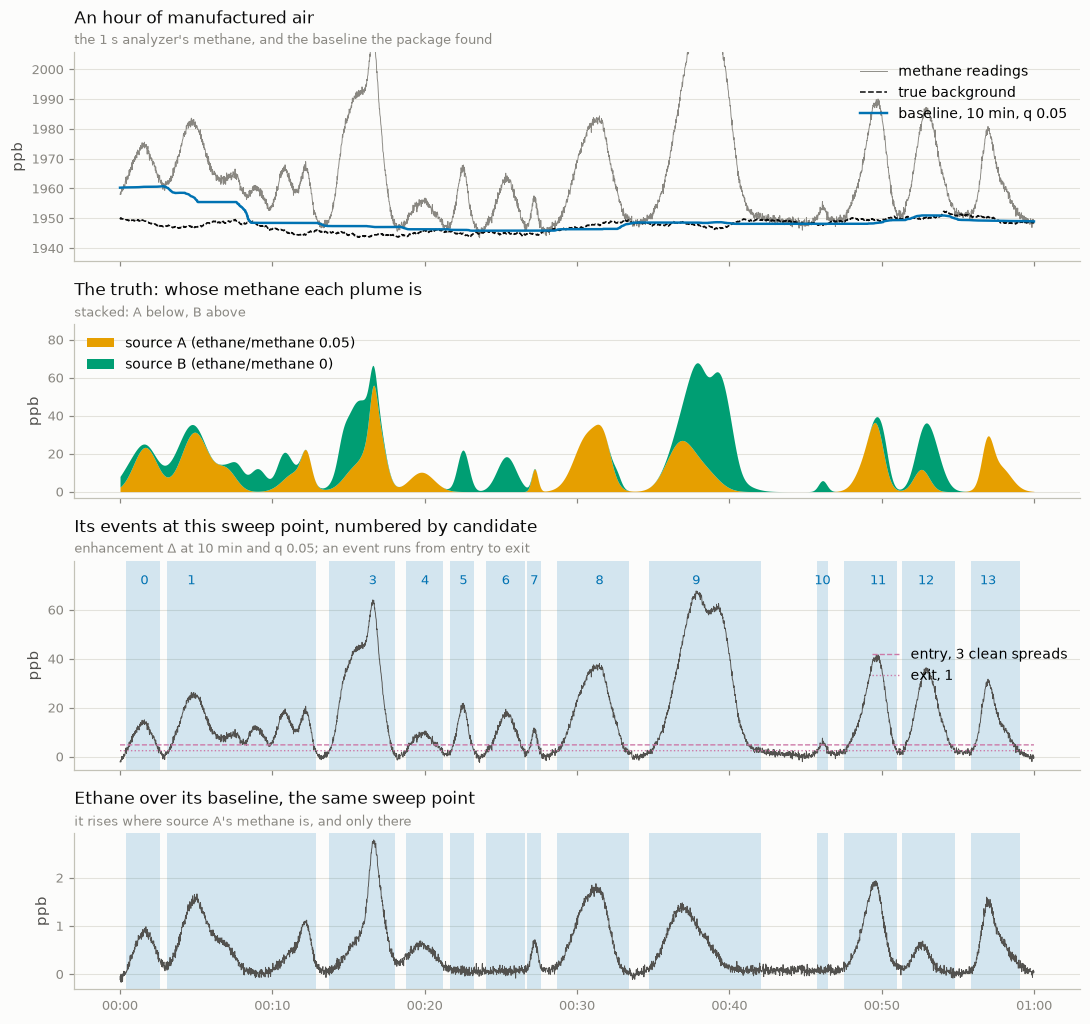

        events  candidates  members  members of A  members of B  members of mixture
2 min      486          18      162            44            36                  82
10 min     354          14      119            34            27                  58
60 min     288          12      108            36            27                  45


In [2]:
start_section("§1")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
WINDOW = 600.0  # the sweep point drawn: baseline window (s): 120, 600 or 3600
QUANTILE = 0.05  # its quantile: 0.01, 0.05 or 0.10
ENTRY = 3.0  # its entry, in clean spreads: 3, 4 or 5
EXIT = 1.0  # its exit: 1, 1.5 or 2

products = chain(seed=SEED)
stream, truth, states = products["stream"], products["truth"], products["states"]
catalog, fits = products["catalog"], products["fits"]
state, found = states["van"], products["events"]["van"]
at = dict(baseline_window=WINDOW, baseline_quantile=QUANTILE)
here = catalog[
    (catalog.species == "ch4")
    & (catalog.baseline_window == WINDOW)
    & (catalog.baseline_quantile == QUANTILE)
    & (catalog.enter_multiple == ENTRY)
    & (catalog.exit_multiple == EXIT)
]
t = stream.time.values
delta = state["enhancement_ch4"].sel(at).values
level = found["clean_level_ch4"].sel(at).values  # one value per reading (per record)
spread = found["clean_spread_ch4"].sel(at).values

fig, axes = plt.subplots(
    4, 1, figsize=(10, 9.4), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1.2, 0.9]}
)
ax = axes[0]
ax.plot(t, stream.ch4.values, color=MUTED, lw=0.6, label="methane readings")
ax.plot(t, truth["background_ch4"], color=INK, ls="--", lw=1, label="true background")
ax.plot(
    t,
    state["baseline_ch4"].sel(at).values,
    color=C1,
    lw=1.6,
    label=f"baseline, {WINDOW / 60:g} min, q {QUANTILE:g}",
)
low = np.nanmin(truth["background_ch4"]) - 8
ax.set_ylim(low, low + 70)  # the background's scale; the tallest plumes run off the top
finish(
    ax,
    title="An hour of manufactured air",
    sub="the 1 s analyzer's methane, and the baseline the package found",
    ylab="ppb",
    legend=True,
)

ax = axes[1]
ax.fill_between(t, 0, truth["A"], color=C2, lw=0, label=f"source A (ethane/methane {RATIO_A:g})")
ax.fill_between(
    t,
    truth["A"],
    truth["A"] + truth["B"],
    color=C3,
    lw=0,
    label=f"source B (ethane/methane {RATIO_B:g})",
)
ax.set_ylim(top=1.3 * np.max(truth["A"] + truth["B"]))
finish(
    ax,
    title="The truth: whose methane each plume is",
    sub="stacked: A below, B above",
    ylab="ppb",
    legend=True,
    loc="upper left",
)

ax = axes[2]
ax.plot(t, delta, color=INK2, lw=0.6)
ax.plot(
    t, level + ENTRY * spread, color=C4, lw=0.9, ls="--", label=f"entry, {ENTRY:g} clean spreads"
)
ax.plot(t, level + EXIT * spread, color=C4, lw=0.9, ls=":", label=f"exit, {EXIT:g}")
top = np.nanmax(delta)
for row in here.itertuples():
    ax.axvspan(row.start_time, row.end_time, color=C1, alpha=0.16, lw=0)
    ax.text(
        row.peak_time,
        1.04 * top,
        row.candidate_id.rsplit("/c", 1)[1],
        ha="center",
        fontsize=8.5,
        color=C1,
    )
ax.set_ylim(-0.08 * top, 1.18 * top)
finish(
    ax,
    title="Its events at this sweep point, numbered by candidate",
    sub=f"enhancement Δ at {WINDOW / 60:g} min and q {QUANTILE:g}; an event runs from "
    f"entry to exit",
    ylab="ppb",
    legend=True,
    loc="center right",
)

ax = axes[3]
ax.plot(t, state["enhancement_c2h6"].sel(at).values, color=INK2, lw=0.6)
for row in here.itertuples():
    ax.axvspan(row.start_time, row.end_time, color=C1, alpha=0.16, lw=0)
finish(
    ax,
    title="Ethane over its baseline, the same sweep point",
    sub="it rises where source A's methane is, and only there",
    ylab="ppb",
)
clock(ax)
plt.tight_layout()
plt.show()

# How many of each, per window: events over all 27 sweep points of the window,
# candidates, and members (each candidate's distinct (quantile, exit) intervals;
# §2). The truth names each member's air: A or B when one source holds at
# least 95 % of its true methane, a mixture otherwise.
york_fits = fits[fits.method == "york"]
share, largest = source_share(york_fits, truth, products["paired"].dataset)
kinds = pd.Series(kind_of(share, largest), index=york_fits.index)
methane = catalog[catalog.species == "ch4"]
counts = pd.DataFrame(
    {
        "events": methane.groupby("baseline_window").size(),
        "candidates": methane.groupby("baseline_window").candidate_id.nunique(),
        "members": york_fits.groupby("baseline_window").size(),
    }
)
counts = counts.join(pd.crosstab(york_fits.baseline_window, kinds).add_prefix("members of "))
counts.index = [f"{w / 60:g} min" for w in counts.index]
print(counts.to_string())

**Read it top to bottom.**

* **The baseline** follows the true background closely, except for the first
  eight minutes, where it sits about 10 ppb high. That is the record's edge:
  a 10-minute window centred on a reading near the start holds only the half
  after it, and here that half is mostly plume. TSARA neither pads nor trims
  an edge (`METHODS.md` §6.4); the count and coverage columns record what
  such a window held.
* **Events** run from the dashed line (entry) down to the dotted one (exit).
  Where plumes crowd, Δ never falls below exit between them, so one event
  holds several plumes: candidate 1 runs ten minutes and holds five, from
  both sources.
* **Ethane** rises only under source A's methane, by 5 % of it. Every ratio
  below is a slope through that relation.

The table counts what the sweep made of the hour. A **member**, the thing
each line is fitted through, is §2's subject. Most members are mixtures
because the plumes in this air overlap often.

In [3]:
# The members by a plain loop over the catalog (written from METHODS.md §5.2),
# against the fits the package made: one row per member and estimator.
reference = reference_members(catalog, "van", "ch4")
check(
    "§1 members are the distinct (candidate, quantile, exit) intervals, named by lowest entry",
    sorted(york_fits.event_id) == sorted(row.event_id for row in reference.values()),
    f"{len(york_fits)} members",
)
check(
    "§1 each member is fitted once per estimator",
    (fits.groupby(["event_id", "method"]).size() == 1).all()
    and set(fits.method) == {"ols", "york"},
    f"{len(fits)} rows",
)

  ✔ §1 members are the distinct (candidate, quantile, exit) intervals, named by lowest entry   [389 members]
  ✔ §1 each member is fitted once per estimator   [778 rows]


**Try it.**

* `WINDOW = 120.0`: the long events split, 18 candidates instead of 14. The
  2-minute baseline climbs into the broad plumes, tens of ppb above the true
  background under the tallest: a short window takes a broad plume's base as
  background.
* `WINDOW = 3600.0`: every window is cut by the record's ends, and the
  baseline is nearly flat (1946.7 to 1948.5 ppb) near the true background.
  12 candidates.
* `ENTRY = 5.0`: the same 13 events as at entry 3, since every one of them
  peaks above 5 clean spreads. An event found at a higher entry is always one
  found at a lower entry (`METHODS.md` §6.8); a weaker plume would drop out.

---
## §2 One candidate: its events, its members, and their points

Take one candidate from §1 and look at all 27 of its events, one per
(quantile, entry, exit) at its window. Two facts of the sweep decide what gets
fitted (`METHODS.md` §5.2, §6.8):

* **A higher entry finds the same interval.** The event at entry 4 is the
  event at entry 3, kept only if its peak reaches 4 clean spreads; its start
  and end are identical. Fitting each entry would fit one interval three
  times.
* **Quantile and exit move the interval.** A higher quantile lifts the
  baseline, so Δ is smaller and the event a little shorter; a higher exit
  ends it sooner.

So a candidate's distinct intervals are its (quantile, exit) pairs, nine at
most. Each is a **member**, named by its lowest entry's `event_id` and fitted
once. A member's **points** are the cells whose midpoint lies inside its
interval: a cell with midpoint $m$ belongs to a member running from
$t_\text{start}$ to $t_\text{end}$ when

$$t_\text{start} \le m < t_\text{end}.$$

On one analyzer those are its own 1 s readings, each read at the member's own
quantile.

The figure: the candidate's enhancement at each quantile, with the truth
beneath it; then each member's interval as one bar.

In [4]:
start_section("§2")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
WINDOW = 600.0  # baseline window (s): 120, 600 or 3600
CANDIDATE = 4  # which candidate at that window, by its number in §1's figure

products = chain(seed=SEED)
catalog, fits, truth = products["catalog"], products["fits"], products["truth"]
pairs = products["paired"].dataset
name = f"van.ch4/w{WINDOW:.0f}s/c{CANDIDATE}"
events = catalog[(catalog.species == "ch4") & (catalog.candidate_id == name)]
members = fits[(fits.candidate_id == name) & (fits.method == "york")]
if events.empty:
    raise ValueError(f"no candidate {CANDIDATE} at {WINDOW:g} s; see §1's figure for the numbers")
print(
    f"candidate {CANDIDATE} at {WINDOW / 60:g} min: {len(events)} events, {len(members)} members\n"
)

# One row per (quantile, exit): the entries its interval is found at, and how
# many distinct intervals those entries report (1 means: copies of one).
table = events.groupby(["baseline_quantile", "exit_multiple"]).agg(
    found_at_entries=("enter_multiple", lambda e: ", ".join(f"{v:g}" for v in sorted(e))),
    distinct_intervals=("start_time", "nunique"),
    start=("start_time", "min"),
    end=("end_time", "max"),
)
by_point = members.set_index(["baseline_quantile", "exit_multiple"])
table["points"] = by_point.n
table["start"] = table.start.dt.strftime("%H:%M:%S")
table["end"] = table.end.dt.strftime("%H:%M:%S")
print(table.to_string())

candidate 4 at 10 min: 27 events, 9 members

                                found_at_entries  distinct_intervals     start       end  points
baseline_quantile exit_multiple                                                                 
0.01              1.0                    3, 4, 5                   1  00:18:39  00:21:12     153
                  1.5                    3, 4, 5                   1  00:18:49  00:21:11     142
                  2.0                    3, 4, 5                   1  00:18:49  00:21:00     131
0.05              1.0                    3, 4, 5                   1  00:18:47  00:21:12     145
                  1.5                    3, 4, 5                   1  00:18:49  00:21:11     142
                  2.0                    3, 4, 5                   1  00:18:52  00:21:00     128
0.10              1.0                    3, 4, 5                   1  00:18:49  00:21:11     142
                  1.5                    3, 4, 5                   1  00:18:52  00

Read across a row: one interval, found at every entry its peak reaches, so one
member. Down the rows: the interval moves by a few seconds with quantile and
exit, and the member's point count with it. A row with fewer than three
entries is an event whose peak stays below the higher entries, or one taken
by a neighbouring candidate at that sweep point (*absorbed*, §6.8).

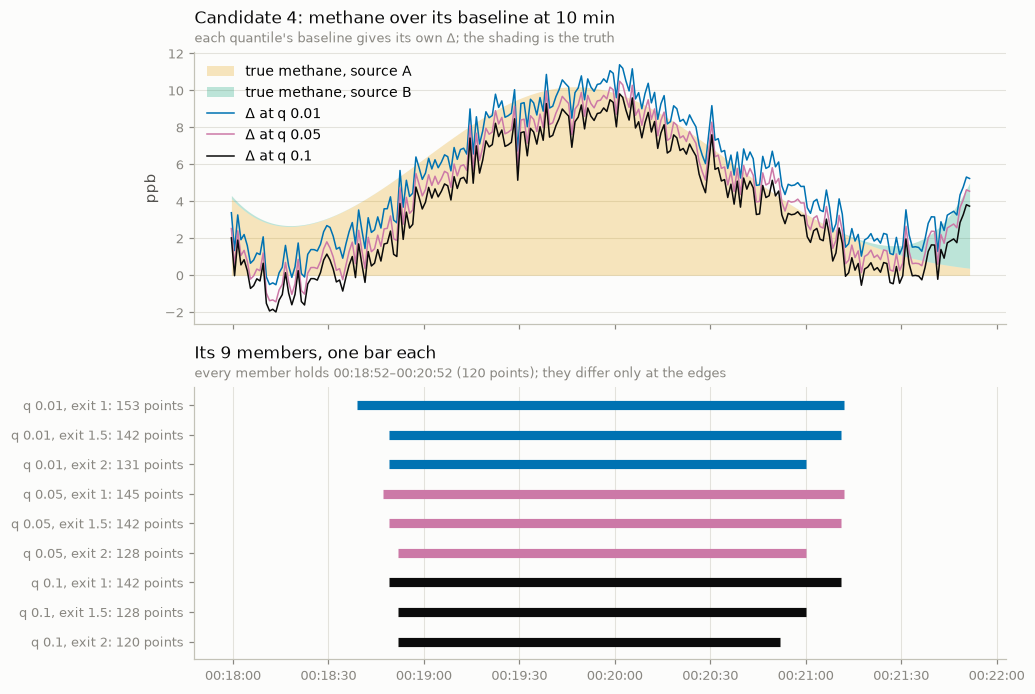

In [5]:
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
lo = events.start_time.min() - pd.Timedelta("40s")
hi = events.end_time.max() + pd.Timedelta("40s")
near = (pairs.time.values >= np.datetime64(lo)) & (pairs.time.values < np.datetime64(hi))
colors = {0.01: C1, 0.05: C4, 0.10: INK}  # the quantiles; amber and green are the sources

fig, (top, bars) = plt.subplots(
    2, 1, figsize=(9.5, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)
tt = pairs.time.values[near]
top.fill_between(
    tt, 0, truth["A"][near], color=C2, alpha=0.25, lw=0, label="true methane, source A"
)
top.fill_between(
    tt,
    truth["A"][near],
    (truth["A"] + truth["B"])[near],
    color=C3,
    alpha=0.25,
    lw=0,
    label="true methane, source B",
)
for q, color in colors.items():
    values = pairs["enhancement_ch4"].sel(baseline_window=WINDOW, baseline_quantile=q).values
    top.plot(tt, values[near], color=color, lw=1, label=f"Δ at q {q:g}")
finish(
    top,
    title=f"Candidate {CANDIDATE}: methane over its baseline at {WINDOW / 60:g} min",
    sub="each quantile's baseline gives its own Δ; the shading is the truth",
    ylab="ppb",
    legend=True,
    loc="upper left",
)

# One bar per member, coloured by its quantile; every member holds the core
# from the latest start to the earliest end, and they differ only at the edges.
ordered = members.sort_values(["baseline_quantile", "exit_multiple"]).reset_index(drop=True)
core_start, core_end = ordered.start_time.max(), ordered.end_time.min()
core = len(reference_points(mid, pd.Timestamp(core_start).value, pd.Timestamp(core_end).value))
for k, m in ordered.iterrows():
    bars.plot(
        [m.start_time, m.end_time],
        [k, k],
        color=colors[m.baseline_quantile],
        lw=6,
        solid_capstyle="butt",
    )
bars.set_yticks(range(len(ordered)))
bars.set_yticklabels(
    [
        f"q {m.baseline_quantile:g}, exit {m.exit_multiple:g}: {int(m.n)} points"
        for m in ordered.itertuples()
    ]
)
bars.set_ylim(len(ordered) - 0.4, -0.6)
finish(
    bars,
    title=f"Its {len(ordered)} members, one bar each",
    sub=f"every member holds {core_start:%H:%M:%S}–{core_end:%H:%M:%S} ({core} points); "
    "they differ only at the edges",
    grid_axis="x",
)
clock(bars, "%H:%M:%S")
plt.tight_layout()
plt.show()

**Each member's points, as a scatter.** The fit is a line through ethane Δ
against methane Δ over a member's points. The nine members share most of their
points (they are nine views of one stretch of air), so their lines differ a
little: that spread across members is the methodological variance a
candidate's ratio will carry (7c2). The blue line is York's fit (§3). The
dashed lines are the two sources' true ratios, each drawn where the member
holds more than 5 % of that source's methane, and through York's intercept, so
that only the slopes are compared: a mixture's air has no one true ratio.

The grey bars are each point's ±1σ on both axes: the readings' own random σ
carried onto the pair cells, which is what York weighs each point by (§3). In
this air the noise is declared constant, so every bar is the same size; with a
σ that grows with the level, tall points would weigh less. The baseline's
error (§6) is not drawn: it is not a bar on each point but a link between
points, which the fit's σ carries separately.

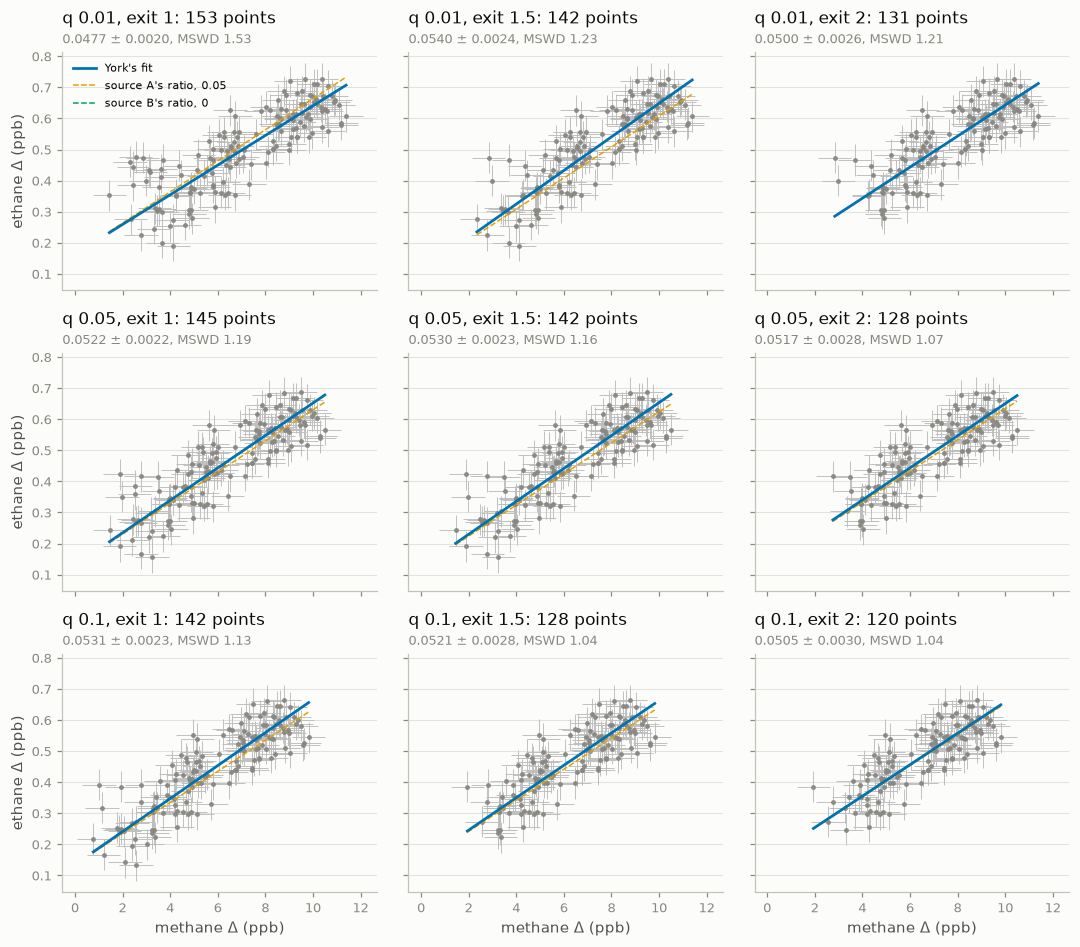

In [6]:
at_q = sorted(members.baseline_quantile.unique())
at_x = sorted(members.exit_multiple.unique())
share, largest = source_share(members, truth, pairs)
fig, axes = plt.subplots(
    len(at_q), len(at_x), figsize=(10, 2.9 * len(at_q)), sharex=True, sharey=True, squeeze=False
)
for i, q in enumerate(at_q):
    for j, x in enumerate(at_x):
        ax = axes[i, j]
        row = members[(members.baseline_quantile == q) & (members.exit_multiple == x)]
        if row.empty:
            ax.set_axis_off()
            continue
        m = row.iloc[0]
        points = reference_points(
            mid, pd.Timestamp(m.start_time).value, pd.Timestamp(m.end_time).value
        )
        at = dict(baseline_window=WINDOW, baseline_quantile=q)
        dx = pairs["enhancement_ch4"].sel(at).values[points]
        dy = pairs["enhancement_c2h6"].sel(at).values[points]
        # Each point's ±1σ: the readings' random σ on the pair cells, York's weights.
        sx = pairs["sigma_rand_ch4"].values[points]
        sy = pairs["sigma_rand_c2h6"].values[points]
        ax.errorbar(
            dx, dy, xerr=sx, yerr=sy, fmt="none", ecolor="#bdbdbd", elinewidth=0.6, zorder=1
        )
        ax.plot(dx, dy, "o", color=MUTED, ms=2.2, alpha=0.9, zorder=2)
        grid = np.array([np.nanmin(dx), np.nanmax(dx)])
        a_share = share[members.index.get_loc(m.name)]
        for ratio, color in ((RATIO_A, C2), (RATIO_B, C3)):
            if (ratio == RATIO_A and a_share > 0.05) or (ratio == RATIO_B and a_share < 0.95):
                ax.plot(grid, m.intercept + ratio * grid, color=color, ls="--", lw=1)
        ax.plot(grid, m.intercept + m.slope * grid, color=C1, lw=1.8)
        if i == 0 and j == 0:
            ax.legend(
                handles=[
                    Line2D([], [], color=C1, lw=1.8, label="York's fit"),
                    Line2D([], [], color=C2, ls="--", lw=1, label=f"source A's ratio, {RATIO_A:g}"),
                    Line2D([], [], color=C3, ls="--", lw=1, label=f"source B's ratio, {RATIO_B:g}"),
                ],
                loc="upper left",
                fontsize=7.5,
            )
        finish(
            ax,
            title=f"q {q:g}, exit {x:g}: {int(m.n)} points",
            sub=f"{m.slope:.4f} ± {m.slope_sigma:.4f}, MSWD {m.mswd:.2f}",
            xlab="methane Δ (ppb)" if i == len(at_q) - 1 else None,
            ylab="ethane Δ (ppb)" if j == 0 else None,
        )
plt.tight_layout()
plt.show()

In [7]:
# Every member's points by the loop above, against the count the fit used (a
# point is used when both enhancements are finite there).
york_fits = fits[fits.method == "york"]
agree = 0
for row in york_fits.itertuples():
    points = reference_points(
        mid, pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
    )
    at = dict(baseline_window=row.baseline_window, baseline_quantile=row.baseline_quantile)
    dx = pairs["enhancement_ch4"].sel(at).values[points]
    dy = pairs["enhancement_c2h6"].sel(at).values[points]
    agree += int((np.isfinite(dx) & np.isfinite(dy)).sum()) == row.n
check(
    "§2 each member's points are the cells whose midpoint its interval holds",
    agree == len(york_fits),
    f"{agree} of {len(york_fits)} members of the hour",
)

same = catalog[catalog.species == "ch4"].groupby(
    ["candidate_id", "baseline_quantile", "exit_multiple"]
)
check(
    "§2 entry copies hold one interval",
    (same.start_time.nunique() == 1).all() and (same.end_time.nunique() == 1).all(),
    f"{same.ngroups} (candidate, quantile, exit) groups",
)

# On the reference's own cells, the midpoint rule is exactly the events
# stage's per-reading index, at every sweep point.
state = products["events"]["van"]
mismatched = 0
for key, group in catalog[catalog.species == "ch4"].groupby(
    ["baseline_window", "baseline_quantile", "enter_multiple", "exit_multiple"]
):
    index = (
        state["event_ch4"]
        .sel(
            baseline_window=key[0],
            baseline_quantile=key[1],
            enter_multiple=key[2],
            exit_multiple=key[3],
        )
        .values
    )
    rebuilt = np.full(mid.size, -1)
    for row in group.itertuples():
        start, end = pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
        rebuilt[reference_points(mid, start, end)] = row.event_number
    mismatched += int((rebuilt != index).sum())
check(
    "§2 on the reference's own cells, midpoint membership is the event index",
    mismatched == 0,
    "every reading of all 81 sweep points",
)

  ✔ §2 each member's points are the cells whose midpoint its interval holds   [389 of 389 members of the hour]
  ✔ §2 entry copies hold one interval   [389 (candidate, quantile, exit) groups]


  ✔ §2 on the reference's own cells, midpoint membership is the event index   [every reading of all 81 sweep points]


**Try it.**

* `CANDIDATE = 1`: ten minutes, five plumes from both sources. Its nine lines
  read 0.077 to 0.082, *above* both sources' ratios. A line through a mixture
  is not held between its sources: it leans on whichever plume reaches
  furthest along methane. On the true background the same members read 0.059
  to 0.061; the rest is the baseline stepping down under this candidate at
  the record's edge (§1).
* `CANDIDATE = 13`: one tall plume of source A. Its nine lines agree closely,
  0.0462 to 0.0474, all a little below 0.05; §3 and §6 show why.
* `CANDIDATE = 6`: source B. Its nine lines lie flat, −0.0012 to −0.0006.
* `SEED = 2`, `CANDIDATE = 5`: six members. At the three lowest (quantile,
  exit) pairs its plume sits inside a 14-minute event that peaks on a far
  taller plume six minutes earlier, so those events belong to candidate 4
  (*absorbed*, `METHODS.md` §6.8).

---
## §3 A line through a member, and what its MSWD says

A member's points are pairs $(x_i, y_i)$: methane's enhancement $x_i$ and
ethane's $y_i$ on one cell, each with its declared random sigma,
$\sigma_{x,i}$ (0.7 ppb here) and $\sigma_{y,i}$ (0.05 ppb). Each member gets
two lines $y = a + b\,x$ through them (`METHODS.md` §4.1–4.2).

**Least squares** chooses $a$ and $b$ to minimize

$$\sum_i \left(y_i - a - b\,x_i\right)^2,$$

each distance measured straight up, as if methane had no noise. Noise on
methane spreads the points sideways, and the slope comes out shrunk toward
zero (*regression dilution*), most where the plume is small beside that noise:

$$b_\text{least squares} \approx b\,
\frac{\operatorname{var}(x_\text{true})}{\operatorname{var}(x_\text{true}) + \sigma_x^2}.$$

It is kept because it is familiar.

**York** chooses $a$ and $b$ to minimize

$$S = \sum_i W_i \left(y_i - a - b\,x_i\right)^2, \qquad
W_i = \frac{1}{\sigma_{y,i}^2 + b^2\,\sigma_{x,i}^2},$$

each distance counted in units of the noise that point should have, on *both*
axes (with no correlation between a point's two errors, as here). This is the
ratio TSARA prefers.

**The MSWD** (mean squared weighted deviation) asks whether the declared noise
explains the scatter about York's line. Each point's **divided residual** is
its distance from the line over the sigma it should have,

$$e_i = \frac{y_i - a - b\,x_i}{\sqrt{\sigma_{y,i}^2 + b^2\,\sigma_{x,i}^2}},
\qquad
\text{MSWD} = \frac{S}{n - 2} = \frac{1}{n - 2}\sum_i e_i^2 .$$

If the air holds one source and the noise is as declared, the $e_i$ behave
like plain noise of standard deviation 1 (about 95 % inside ±2, no slow
pattern), and the MSWD is near 1. It scatters by chance, so the gate is the
99 % point of that chance: a member is called one source when

$$\text{MSWD} \le \frac{\chi^2_{0.99,\;n-2}}{n - 2}$$

(`mswd_gate` in the setup cell; 1.25 to 1.4 for these members).

Four candidates of §1, side by side at one sweep point: on top each member's
scatter and lines, below its divided residuals $e_i$ in the order the van met
them, with a 31-point running mean (purple) to show slow structure. Printed
after the figure: each member refitted on the *true* background the recipe
kept, which takes the baseline's error away.

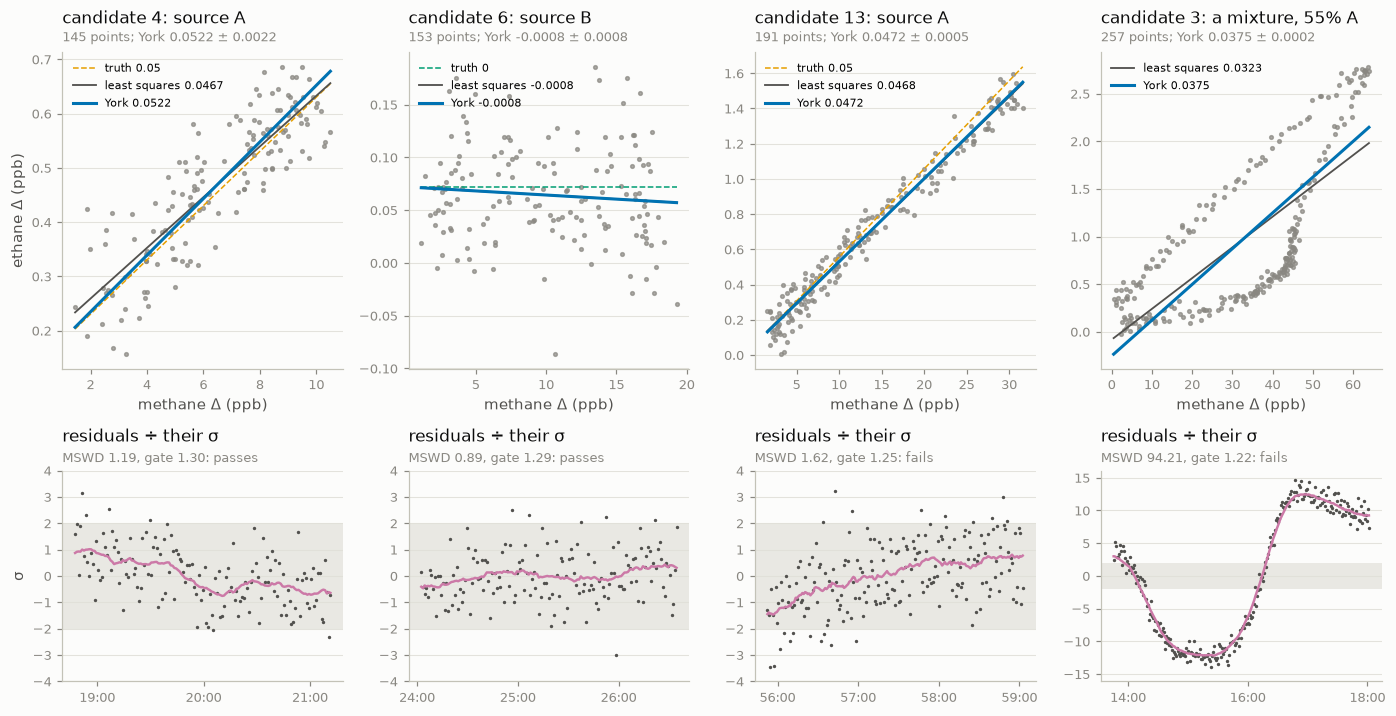

York on the package's baseline, then on the true background (verdicts in that order):
               air share A  slope on the baseline  MSWD  slope on the true background  MSWD   gate          verdict
candidate                                                                                                          
4                A  100.0%                 0.0522  1.19                        0.0490   0.81  1.30  passes / passes
6                B    0.0%                -0.0008  0.89                       -0.0002   0.83  1.29  passes / passes
13               A  100.0%                 0.0472  1.62                        0.0496   1.22  1.25   fails / passes
3          mixture   55.5%                 0.0375 94.21                        0.0381  81.93  1.22    fails / fails


In [8]:
start_section("§3")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
WINDOW = 600.0  # the sweep point: baseline window (s),
QUANTILE = 0.05  # quantile,
EXIT = 1.0  # and exit (each candidate's member at this point is drawn)
CANDIDATES = [4, 6, 13, 3]  # four candidates by their number in §1's figure

products = chain(seed=SEED)
fits, truth = products["fits"], products["truth"]
pairs = products["paired"].dataset
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
at = dict(baseline_window=WINDOW, baseline_quantile=QUANTILE)
point = fits[
    (fits.baseline_window == WINDOW)
    & (fits.baseline_quantile == QUANTILE)
    & (fits.exit_multiple == EXIT)
]
share, largest = source_share(point, truth, pairs)
point = point.assign(kind=kind_of(share, largest), share_a=share)

fig, axes = plt.subplots(
    2,
    len(CANDIDATES),
    figsize=(3.2 * len(CANDIDATES), 6.6),
    gridspec_kw={"height_ratios": [1.5, 1]},
    squeeze=False,
)
shown = {}
for col, number in enumerate(CANDIDATES):
    rows = point[point.candidate_id == f"van.ch4/w{WINDOW:.0f}s/c{number}"].set_index("method")
    if rows.empty:
        raise ValueError(f"candidate {number} has no member at this sweep point")
    york_row, ols_row = rows.loc["york"], rows.loc["ols"]
    points = reference_points(
        mid, pd.Timestamp(york_row.start_time).value, pd.Timestamp(york_row.end_time).value
    )
    dx = pairs["enhancement_ch4"].sel(at).values[points]
    dy = pairs["enhancement_c2h6"].sel(at).values[points]
    sx, sy = pairs["sigma_rand_ch4"].values[points], pairs["sigma_rand_c2h6"].values[points]

    ax = axes[0, col]
    ax.plot(dx, dy, "o", color=MUTED, ms=2.4, alpha=0.7)
    grid = np.array([np.nanmin(dx), np.nanmax(dx)])
    if york_row.kind in ("A", "B"):  # a single source's true line; a mixture has none
        ratio, color = (RATIO_A, C2) if york_row.kind == "A" else (RATIO_B, C3)
        ax.plot(
            grid,
            york_row.intercept + ratio * grid,
            color=color,
            ls="--",
            lw=1,
            label=f"truth {ratio:g}",
        )
    ax.plot(
        grid,
        ols_row.intercept + ols_row.slope * grid,
        color=INK2,
        lw=1.2,
        label=f"least squares {ols_row.slope:.4f}",
    )
    ax.plot(
        grid,
        york_row.intercept + york_row.slope * grid,
        color=C1,
        lw=2,
        label=f"York {york_row.slope:.4f}",
    )
    kind = {
        "A": "source A",
        "B": "source B",
        "mixture": f"a mixture, {york_row.share_a:.0%} A",
        "none": "no plume",
    }[york_row.kind]
    finish(
        ax,
        title=f"candidate {number}: {kind}",
        sub=f"{int(york_row.n)} points; York {york_row.slope:.4f} ± {york_row.slope_sigma:.4f}",
        xlab="methane Δ (ppb)",
        ylab="ethane Δ (ppb)" if col == 0 else None,
    )
    ax.legend(loc="upper left", fontsize=7.5)

    # York's residuals, each divided by the sigma it should have.
    residual = (dy - york_row.intercept - york_row.slope * dx) / np.sqrt(
        sy**2 + york_row.slope**2 * sx**2
    )
    ax = axes[1, col]
    tt = pairs.time.values[points]
    ax.axhspan(-2, 2, color=GRID, alpha=0.7, lw=0)
    ax.plot(tt, residual, ".", color=INK2, ms=2.4)
    ax.plot(
        tt, pd.Series(residual).rolling(31, center=True, min_periods=10).mean(), color=C4, lw=1.6
    )
    edge = max(4.0, 1.1 * np.nanmax(np.abs(residual)))
    ax.set_ylim(-edge, edge)
    gate = float(mswd_gate(york_row.dof))
    finish(
        ax,
        title="residuals ÷ their σ",
        sub=f"MSWD {york_row.mswd:.2f}, gate {gate:.2f}: "
        f"{'passes' if york_row.mswd <= gate else 'fails'}",
        ylab="σ" if col == 0 else None,
    )
    few_ticks(ax)
    clock(ax, "%M:%S")
    shown[number] = (york_row, residual)
plt.tight_layout()
plt.show()

# Each member refitted on the true background the recipe kept, beside its fit
# on the package's baseline: what is left once the baseline's error is gone.
stream = products["stream"]
refits = []
for number, (row, _) in shown.items():
    points = reference_points(
        mid, pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
    )
    rows = np.searchsorted(stream.time.values, pairs.time.values[points])
    line = york(
        stream.ch4.values[rows] - truth["background_ch4"][rows],
        stream.c2h6.values[rows] - truth["background_c2h6"][rows],
        pairs["sigma_rand_ch4"].values[points],
        pairs["sigma_rand_c2h6"].values[points],
    )
    gate = float(mswd_gate(row.dof))
    refits.append(
        {
            "candidate": number,
            "air": row.kind,
            "share A": row.share_a,
            "slope on the baseline": row.slope,
            "MSWD": row.mswd,
            "slope on the true background": line.slope[0],
            "MSWD ": line.mswd[0],
            "gate": gate,
            "verdict": ("passes" if row.mswd <= gate else "fails")
            + " / "
            + ("passes" if line.mswd[0] <= gate else "fails"),
        }
    )
refits = pd.DataFrame(refits).set_index("candidate")
print("York on the package's baseline, then on the true background (verdicts in that order):")
print(
    refits.to_string(
        formatters={"share A": "{:.1%}".format},
        float_format=lambda v: f"{v:.4f}" if abs(v) < 0.5 else f"{v:.2f}",
    )
)

**Read the columns.**

* **Source A, a small plume.** The points scatter widely, since methane's
  noise is large beside a 10 ppb plume, but about York's line, which sits
  near the truth. Least squares reads lower: noise on methane spreads the
  points sideways and flattens a vertical-distance fit. The residuals are
  mostly noise, with a gentle drift (purple) small beside it; the MSWD passes.
* **Source B.** No ethane: the line is flat, its slope consistent with 0.
  That is a result, an upper limit on this source's ethane (`METHODS.md` §5.5).
* **Source A, a tall plume, failing its gate.** One source, yet the MSWD is
  above the gate and the slope sits below 0.05 by six of its σ. This is a
  **false alarm** of the one-source test, and no widening of the σ (§5) would
  cure it. The residuals show why: not two branches, but a slow drift across
  the member (purple), from −1.5 to +1. Something besides the readings' noise
  changes across the plume: the **baseline's** error. Its enhancement is the
  reading minus a baseline, and here the methane baseline climbs about 2 ppb
  against the true background across the member while the ethane baseline
  stays put, so the points slide along methane differently on the plume's way
  up and its way down, and the line tilts. Refitted on the true background (the
  table above), the same member reads 0.0496 at an MSWD of 1.22, inside its
  gate. The small plume beside it drifts too, but there the readings' noise is
  large beside the drift, so it hides. §6 counts how often this happens, and
  shows the term 7c2 adds for it.
* **A mixture.** Two sources, two branches (the upper one at source A's
  0.05, the lower one source B's methane): the line runs between them and is
  neither source's ratio. Its residuals swing far outside ±2 in long runs, and
  the MSWD is many times the gate, which is the gate doing its job.

The fit stores, beside each line, every number a gate or the uncertainty will
read, so that gating is a threshold applied later and never a refit
(`METHODS.md` §5.2–5.3). For these four members:

In [9]:
stored = [
    "n",
    "signal",
    "peak_z",
    "candidate_peak_z",
    "slope",
    "slope_sigma",
    "intercept",
    "mswd",
    "dof",
    "r_squared",
]
print(pd.DataFrame({f"c{k}": row[stored] for k, (row, _) in shown.items()}).to_string())

                        c4         c6        c13         c3
n                      145        153        191        257
signal            3.203104   7.536634  12.926138  25.830937
peak_z            7.846694  15.252512  25.653342  52.963804
candidate_peak_z  8.478698  16.331129  27.411018  56.446041
slope             0.052173  -0.000778   0.047221    0.03752
slope_sigma       0.002238   0.000762    0.00048   0.000198
intercept         0.130339   0.072118   0.056949  -0.253526
mswd              1.185879   0.893268   1.617156  94.213597
dof                    143        151        189        255
r_squared         0.734587   0.007427   0.969005   0.539884


| number | what it is |
|---|---|
| `n` | the points used: both enhancements finite |
| `signal` | how far methane swings inside the member, in units of its noise: $\sqrt{\max\left(0,\ \operatorname{var}(x) \,/\, \overline{\sigma_x^2} - 1\right)}$, the variance on $n - 1$ (§7) |
| `peak_z`, `candidate_peak_z` | the member's own peak in clean spreads, and its candidate's tallest (§7) |
| `slope`, `slope_sigma`, `intercept` | York's line and the slope's standard error *as York computes it*, from the declared noise alone (§4) |
| `mswd`, `dof` | the number above, on $n - 2$ degrees of freedom |
| `r_squared` | the familiar one; it does not judge a ratio (a source B member, ratio 0, has r² near 0) |

In [10]:
# The stored lines are the estimators' own on each member's points alone, and
# the MSWD is the mean of the squared residuals drawn above, over n - 2.
same, mswd_ok = 0, 0
for number, (row, residual) in shown.items():
    points = reference_points(
        mid, pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
    )
    dx = pairs["enhancement_ch4"].sel(at).values[points]
    dy = pairs["enhancement_c2h6"].sel(at).values[points]
    sx, sy = pairs["sigma_rand_ch4"].values[points], pairs["sigma_rand_c2h6"].values[points]
    alone = {"york": york(dx, dy, sx, sy), "ols": ols(dx, dy, sx, sy)}
    both = point[point.event_id == row.event_id].set_index("method")
    same += all(
        np.array_equal(both.loc[m, f], getattr(alone[m], f)[0], equal_nan=True)
        for m in alone
        for f in ("slope", "intercept", "slope_sigma", "r_squared")
    )
    used = np.isfinite(residual)
    mswd_ok += math.isclose(np.sum(residual[used] ** 2) / (used.sum() - 2), row.mswd, rel_tol=1e-9)
check(
    "§3 the stored lines are York's and least squares' on the member's points alone",
    same == len(shown),
    f"{same} of {len(shown)} members: slope, intercept, sigma, r2",
)
check(
    "§3 the MSWD is the mean squared divided residual over n - 2",
    mswd_ok == len(shown),
    f"{mswd_ok} of {len(shown)}",
)

york_fits = fits[fits.method == "york"]
check(
    "§3 dof is n - 2, and least squares' row carries York's MSWD",
    (york_fits.dof == york_fits.n - 2).all()
    and np.array_equal(
        fits[fits.method == "ols"].mswd.values, york_fits.mswd.values, equal_nan=True
    ),
)
pure = refits[(refits["share A"] >= 0.999) | (refits["share A"] <= 0.001)]
check(
    "§3 every member shown that is 99.9 % one source passes its gate on the true background",
    bool((pure["MSWD "] <= pure.gate).all()),
    f"{len(pure)} members",
)
check(
    "§3 every fit names its sigmas as the recipe declared them",
    set(york_fits.reference_sigma_provenance)
    == set(york_fits.numerator_sigma_provenance)
    == {"declared"},
    f"{len(york_fits)} York fits",
)
check(
    "§3 every row carries its candidate's tallest member's height",
    (york_fits.candidate_peak_z == york_fits.groupby("candidate_id").peak_z.transform("max")).all(),
    f"{york_fits.candidate_id.nunique()} candidates",
)
row = york_fits.iloc[0]
points = reference_points(mid, pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value)
here = dict(baseline_window=row.baseline_window, baseline_quantile=row.baseline_quantile)
dx = pairs["enhancement_ch4"].sel(here).values[points]
sx = pairs["sigma_rand_ch4"].values[points]
used = np.isfinite(dx) & np.isfinite(pairs["enhancement_c2h6"].sel(here).values[points])
signal = math.sqrt(max(0.0, np.var(dx[used], ddof=1) / np.mean(sx[used] ** 2) - 1))
check(
    "§3 the signal is sqrt(max(0, var(dx)/mean(sigma_x^2) - 1)), variance on n - 1",
    math.isclose(row.signal, signal, rel_tol=1e-12),
    f"{signal:.2f}",
)

  ✔ §3 the stored lines are York's and least squares' on the member's points alone   [4 of 4 members: slope, intercept, sigma, r2]
  ✔ §3 the MSWD is the mean squared divided residual over n - 2   [4 of 4]
  ✔ §3 dof is n - 2, and least squares' row carries York's MSWD
  ✔ §3 every member shown that is 99.9 % one source passes its gate on the true background   [3 members]
  ✔ §3 every fit names its sigmas as the recipe declared them   [389 York fits]
  ✔ §3 every row carries its candidate's tallest member's height   [44 candidates]
  ✔ §3 the signal is sqrt(max(0, var(dx)/mean(sigma_x^2) - 1)), variance on n - 1   [3.53]


**Try it.**

* `CANDIDATES = [8, 9, 11, 12]`: candidate 8 is 97 % source A and York reads
  0.0497, yet its MSWD (3.7) fails: the 3 % of source B, in the plume's last
  minute, bends the residuals down to −4. It fails on the true background
  too (the table): this time the cause is the air, not the baseline. Candidate 9's points trace a loop,
  its two sources' plumes rising and falling at different times; 11 and 12
  are mixtures too.
* `QUANTILE = 0.10`: the same four members on a higher baseline. The slopes
  move by at most 0.0017, and every verdict stays.
* `WINDOW = 120.0` with `CANDIDATES = [5, 6, 7, 8]` (the numbers are per
  window): candidate 7, one small plume of source A, reads 0.037 and fails
  its gate. The table shows it on the true background reading 0.048 at an
  MSWD of 0.89: the baseline's error again, larger at a short window (§6).

---
## §4 What a slope's σ promises

A σ is a promise about repeats: **measure the same air again, with fresh
noise, and the slope $\hat b$ moves by about $\sigma_b$**, so that over many
repeats

$$\Pr\left(|\hat b - b| \le \sigma_b\right) \approx 0.68, \qquad
\Pr\left(|\hat b - b| \le 2\sigma_b\right) \approx 0.95 .$$

York computes that promise from the declared noise alone,

$$\sigma_b = \frac{1}{\sqrt{\sum_i W_i\, u_i^2}},$$

with §3's weights $W_i$ and $u_i$ each point's distance along methane from
their weighted mean (taken on York's adjusted points, `METHODS.md` §4.2). It
never looks at how the points actually scatter about the line. So the way to
test it is to repeat the measurement, which in the air is impossible and here
is easy.

The recipe knows each member's true air: its true methane and ethane
enhancement at every second, before noise. Take §3's tall plume of source A,
keep its true air, draw the analyzer's noise afresh 2,000 times, and fit each
draw through the package (`repeat_fits` in the setup cell). The enhancements
are the readings minus the *true* background, so that only the noise changes
from repeat to repeat; the baseline's error is §6's.

The figure draws the 2,000 slopes from each estimator, and over them the bell
curve that the σ promises: centred on the true ratio, as wide as the median σ
the fits reported.

candidate 13's member: 191 readings, true methane up to 29 ppb, signal 12.9, 100% source A

                      York  least squares
mean slope            0.05        0.04968
slopes' spread   0.0005008      0.0004966
median σ         0.0005092      0.0005068
spread ÷ σ          0.9836           0.98
truth within ±2σ     0.956          0.907


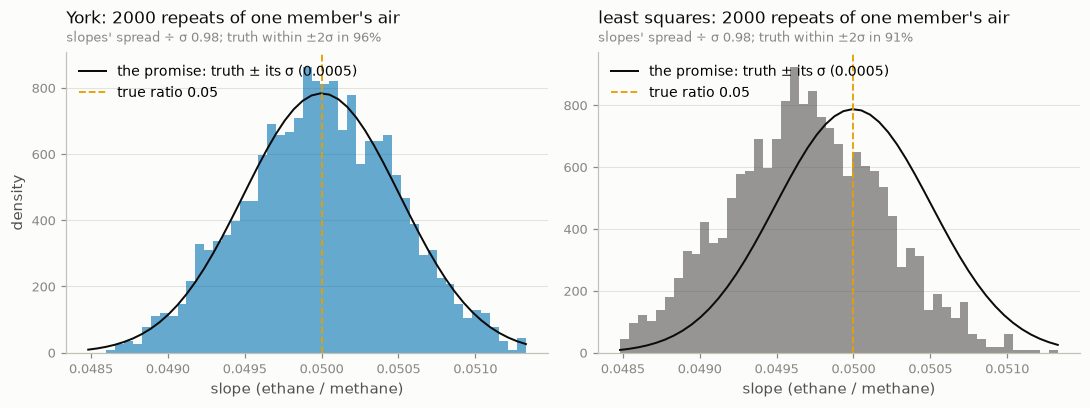

  ✔ §4 York's slope is unbiased on one source: its mean within 3 standard errors of the truth   [0.05000 against 0.05]
  ✔ §4 York's sigma keeps its promise where the signal is strong (at least 5)   [spread ÷ σ 0.98, signal 12.9]


In [11]:
start_section("§4")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour the member comes from
CANDIDATE = 13  # whose member, by its number in §1's figure (at 10 min, q 0.05, exit 1)
REPEATS = 2000  # how many times the noise is drawn again

products = chain(seed=SEED)
fits, truth, pairs = products["fits"], products["truth"], products["paired"].dataset
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
member = fits[
    (fits.method == "york")
    & (fits.candidate_id == f"van.ch4/w600s/c{CANDIDATE}")
    & (fits.baseline_quantile == 0.05)
    & (fits.exit_multiple == 1.0)
].iloc[0]
points = np.asarray(
    reference_points(
        mid, pd.Timestamp(member.start_time).value, pd.Timestamp(member.end_time).value
    )
)
a, b = truth["A"][points], truth["B"][points]
x_true, y_true = a + b, RATIO_A * a + RATIO_B * b  # the member's true air, before noise
true_ratio = RATIO_A if a.sum() >= b.sum() else RATIO_B  # the source holding most of its methane

repeats, _ = repeat_fits(x_true, y_true, REPEATS, seed=SEED)
print(
    f"candidate {CANDIDATE}'s member: {len(points)} readings, "
    f"true methane up to {x_true.max():.0f} ppb, "
    f"signal {member.signal:.1f}, {a.sum() / (a.sum() + b.sum()):.0%} source A\n"
)
summary = {}
for method in ("york", "ols"):
    rows = repeats[repeats.method == method]
    spread = np.std(rows.slope, ddof=1)
    summary[method] = {
        "mean slope": rows.slope.mean(),
        "slopes' spread": spread,
        "median σ": np.median(rows.slope_sigma),
        "spread ÷ σ": spread / np.median(rows.slope_sigma),
        "truth within ±2σ": np.mean(np.abs(rows.slope - true_ratio) <= 2 * rows.slope_sigma),
    }
print(
    pd.DataFrame(summary)
    .rename(columns={"york": "York", "ols": "least squares"})
    .to_string(float_format=lambda v: f"{v:.4g}")
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
low, high = np.percentile(repeats.slope, [0.2, 99.8])
bins = np.linspace(low, high, 50)
for ax, method, color, name in (
    (axes[0], "york", C1, "York"),
    (axes[1], "ols", INK2, "least squares"),
):
    rows = repeats[repeats.method == method]
    sigma = np.median(rows.slope_sigma)
    ax.hist(rows.slope, bins=bins, density=True, color=color, alpha=0.6)
    curve = np.exp(-0.5 * ((bins - true_ratio) / sigma) ** 2) / (sigma * math.sqrt(2 * math.pi))
    ax.plot(bins, curve, color=INK, lw=1.3, label=f"the promise: truth ± its σ ({sigma:.4f})")
    ax.axvline(true_ratio, color=C2, ls="--", lw=1.2, label=f"true ratio {true_ratio:g}")
    finish(
        ax,
        title=f"{name}: {REPEATS} repeats of one member's air",
        sub=f"slopes' spread ÷ σ {summary[method]['spread ÷ σ']:.2f}; "
        f"truth within ±2σ in {summary[method]['truth within ±2σ']:.0%}",
        xlab="slope (ethane / methane)",
        legend=True,
        loc="upper left",
    )
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

york_rows = repeats[repeats.method == "york"]
spread = np.std(york_rows.slope, ddof=1)
check(
    "§4 York's slope is unbiased on one source: its mean within 3 standard errors of the truth",
    abs(york_rows.slope.mean() - true_ratio) <= 3 * spread / math.sqrt(len(york_rows)),
    f"{york_rows.slope.mean():.5f} against {true_ratio:g}",
)
check(
    "§4 York's sigma keeps its promise where the signal is strong (at least 5)",
    member.signal < 5 or 0.9 <= summary["york"]["spread ÷ σ"] <= 1.15,
    f"spread ÷ σ {summary['york']['spread ÷ σ']:.2f}, signal {member.signal:.1f}"
    if member.signal >= 5
    else f"not asked: signal {member.signal:.1f}",
)

**York keeps its promise**: its slopes centre on the truth and spread as far as
its σ says. **Least squares' σ is honest about its own slopes, but its slopes
centre a little below the truth** (0.0497): noise on methane flattens a
vertical-distance fit (§3), so its promise is about a slightly wrong number,
and the truth falls inside its ±2σ in 91 % of repeats, not 95 %. On a tall
plume the shortfall is small; the first Try-it shows a small plume.

That promise rests on two assumptions, both true here because the recipe made
them so: **the declared noise is the true noise**, and **each reading's noise
is fresh**, independent of the last. A real analyzer may break either. §5
breaks each in turn and shows the widening that repairs it.

**Try it.**

* `CANDIDATE = 4`: §3's small plume, signal 3.2. York's slopes spread 1.05
  times its σ: a little more than promised, as `METHODS.md` §4.5 Table 5
  measured where the reference swings only a few times its noise (the signal
  gate's reason, §7). Least squares' slopes centre on 0.046, and the truth
  falls inside its ±2σ in only 52 % of the repeats.
* `CANDIDATE = 6`: source B, true ratio 0. Both estimators centre on 0: no
  ethane means nothing for noise on methane to flatten.

---
## §5 Widening the σ, one broken assumption at a time

The fit stores York's σ as it comes and a **widened** σ beside it, with every
factor used (`METHODS.md` §5.4):

$$\sigma_{b,\text{widened}} = \sigma_b\; P\; \sqrt{\max\left(1,\ \text{MSWD} / E\right)} .$$

Each factor repairs one of §4's two assumptions. This section breaks them one
at a time on the same member, repeats the noise, and checks the widened σ
against the slopes' real spread.

### (a) The noise is declared too small: the Birge factor

If the noise is twice what was declared, the points scatter twice as far from
the line as York expects. Every divided residual of §3 is then about twice its
size, so the **MSWD**, their mean square, reads about 4 instead of 1. York's σ
is half the slopes' real spread, since it was computed from the declared
noise. The fix uses the one place the truth shows: multiply σ by
$\sqrt{\text{MSWD}}$. It is floored at 1 so that a generously declared noise
never *narrows* a σ: the **Birge factor** $\sqrt{\max(1,\ \text{MSWD})}$, with
$E = 1$ here ($E$ is part (b)).

noise declared at 0.5 of the truth: median MSWD 3.98, median Birge factor 1.99
  York's σ as it comes  : slopes' spread ÷ σ 1.97, truth within ±2σ in 69%
  widened               : slopes' spread ÷ σ 0.99, truth within ±2σ in 96%


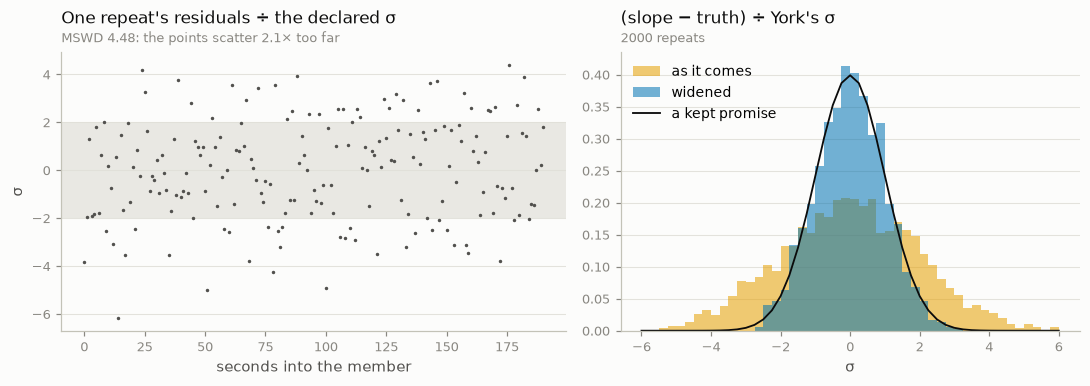

  ✔ §5 the Birge factor is sqrt(max(1, MSWD / E)) for every repeat
  ✔ §5 with the noise declared wrong, the widened sigma keeps its promise   [spread ÷ widened σ 0.99]


In [12]:
start_section("§5")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour the member comes from
CANDIDATE = 13  # whose member (at 10 min, q 0.05, exit 1)
REPEATS = 2000  # how many times the noise is drawn again
DECLARED = 0.5  # (a) the noise told to the fit, as a multiple of the true noise

products = chain(seed=SEED)
fits, truth, pairs = products["fits"], products["truth"], products["paired"].dataset
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
member = fits[
    (fits.method == "york")
    & (fits.candidate_id == f"van.ch4/w600s/c{CANDIDATE}")
    & (fits.baseline_quantile == 0.05)
    & (fits.exit_multiple == 1.0)
].iloc[0]
points = np.asarray(
    reference_points(
        mid, pd.Timestamp(member.start_time).value, pd.Timestamp(member.end_time).value
    )
)
a, b = truth["A"][points], truth["B"][points]
x_true, y_true = a + b, RATIO_A * a + RATIO_B * b
true_ratio = RATIO_A if a.sum() >= b.sum() else RATIO_B


def honesty(rows, column):
    """Return the slopes' spread over their median sigma (1: honest), the truth's share in ±2."""
    return (
        np.std(rows.slope, ddof=1) / np.median(rows[column]),
        np.mean(np.abs(rows.slope - true_ratio) <= 2 * rows[column]),
    )


repeats, (noise_x, noise_y) = repeat_fits(x_true, y_true, REPEATS, declared=DECLARED, seed=SEED)
york_rows = repeats[repeats.method == "york"].reset_index(drop=True)
print(
    f"noise declared at {DECLARED:g} of the truth: median MSWD {np.median(york_rows.mswd):.2f}, "
    f"median Birge factor {np.median(york_rows.birge_factor):.2f}"
)
for label, column in (("York's σ as it comes", "slope_sigma"), ("widened", "slope_sigma_widened")):
    ratio, inside = honesty(york_rows, column)
    print(f"  {label:22s}: slopes' spread ÷ σ {ratio:.2f}, truth within ±2σ in {inside:.0%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
first = york_rows.iloc[0]
x, y = x_true + noise_x[0], y_true + noise_y[0]
divided = (y - first.intercept - first.slope * x) / np.sqrt(
    (0.05 * DECLARED) ** 2 + first.slope**2 * (0.7 * DECLARED) ** 2
)
ax = axes[0]
ax.axhspan(-2, 2, color=GRID, alpha=0.7, lw=0)
ax.plot(np.arange(x.size), divided, ".", color=INK2, ms=2.5)
finish(
    ax,
    title="One repeat's residuals ÷ the declared σ",
    sub=f"MSWD {first.mswd:.2f}: the points scatter {math.sqrt(first.mswd):.1f}× too far",
    xlab="seconds into the member",
    ylab="σ",
)
ax = axes[1]
bins = np.linspace(-6, 6, 49)
for column, color, label in (
    ("slope_sigma", C2, "as it comes"),
    ("slope_sigma_widened", C1, "widened"),
):
    ax.hist(
        np.clip((york_rows.slope - true_ratio) / york_rows[column], -6, 6),
        bins=bins,
        density=True,
        color=color,
        alpha=0.55,
        label=label,
    )
ax.plot(
    bins, np.exp(-0.5 * bins**2) / math.sqrt(2 * math.pi), color=INK, lw=1.2, label="a kept promise"
)
finish(
    ax,
    title="(slope − truth) ÷ York's σ",
    sub=f"{REPEATS} repeats",
    xlab="σ",
    legend=True,
    loc="upper left",
)
plt.tight_layout()
plt.show()

check(
    "§5 the Birge factor is sqrt(max(1, MSWD / E)) for every repeat",
    np.allclose(
        york_rows.birge_factor,
        np.sqrt(np.maximum(1.0, york_rows.mswd / york_rows.mswd_expected)),
        rtol=1e-12,
        atol=0,
    ),
)
ratio, _ = honesty(york_rows, "slope_sigma_widened")
check(
    "§5 with the noise declared wrong, the widened sigma keeps its promise",
    member.signal < 5 or 0.9 <= ratio <= 1.2,
    f"spread ÷ widened σ {ratio:.2f}",
)

### (b) The noise lingers: the persistence factor P, and the expected MSWD E

An analyzer whose cell takes a few seconds to flush carries part of each
reading's error into the next. The noise is then the same size as declared,
but it **lingers**: its lag-one correlation $\rho$ is above 0, and its
**decorrelation time** $\tau$ says for how long. On readings $\Delta t$ = 1 s
apart the two are one number,

$$\rho = e^{-\Delta t / \tau}, \qquad \tau = -\frac{\Delta t}{\ln \rho}$$

($\rho$ 0.7 is $\tau$ 2.8 s), and two readings $|t_i - t_j|$ apart have errors
correlated by $R_{ij} = e^{-|t_i - t_j| / \tau}$.
Below, left: fresh noise and lingering noise of the same size; right: one
repeat's residuals with lingering noise, which look perfectly ordinary.

That is the trouble. Each residual is still the declared size, so the MSWD
stays near 1, and the Birge factor sees nothing. Yet 191 readings whose noise
lingers carry less independent information than 191 fresh ones, and the
slopes spread further than York's σ promises. Only the declared τ can tell the
fit, and two numbers follow from it:

* **P, the persistence factor**: how much further a slope fitted to these
  points spreads when the noise lingers for $\tau$,

  $$P = \sqrt{\frac{v^\mathsf{T} R\, v}{v^\mathsf{T} v}}, \qquad
  v_i = \sqrt{W_i}\,\left(x_i - \bar x_W\right),$$

  from the member's own methane values $x_i$, their $W$-weighted mean
  $\bar x_W$ and their times, through $R$ (`METHODS.md` §5.4). It is a little
  smaller than the factor for an *average* of the same readings,

  $$\sqrt{N / N_\text{eff}}, \qquad
  N_\text{eff} = \frac{N}{1 + 2\sum_{k=1}^{N-1}\left(1 - k/N\right)\rho^{k}}$$

  (`METHODS.md` §3.4), because noise that lingers lifts a whole stretch of
  points together, and a stretch long beside the plume moves the line up or
  down (its intercept) more than it tilts it.
* **E, the MSWD a single source is expected to read** under that persistence,

  $$E = \frac{n - s^\mathsf{T} R\, s \,/\, \sum_i W_i - P^2}{n - 2}, \qquad s_i = \sqrt{W_i},$$

  which is a little below 1, since the line follows part of the slow noise. The Birge
  factor reads the MSWD against $E$, not against 1, so that an understated
  noise is still seen when the noise also lingers.

With fresh noise $R$ is the identity, and both factors are exactly 1.

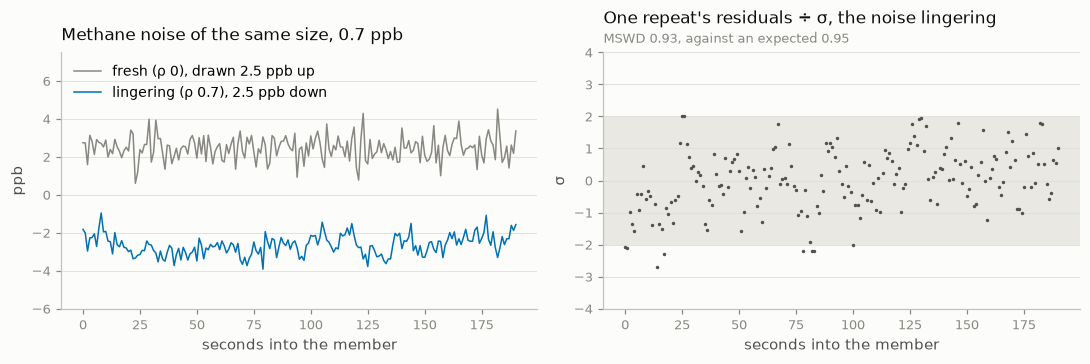

   ρ  τ (s)  spread ÷ York's σ  P, the slope's own  an average's √(N/N_eff)    E  MSWD  spread ÷ widened σ  truth within ±2 widened σ
0.00    inf               0.98                1.00                     1.00 1.00  0.99                0.98                       0.96
0.50   1.44               1.68                1.72                     1.73 0.98  0.97                0.97                       0.97
0.70   2.80               2.28                2.33                     2.36 0.95  0.94                0.96                       0.97
0.90   9.49               3.85                3.93                     4.25 0.83  0.79                0.95                       0.97


In [13]:
# --- parameters --------------------------------------------------------------
RHO = 0.7  # (b) lag-one correlation of the noise on 1 s readings, both gases (0: fresh)
DECLARE_TAU = True  # tell the fit the decorrelation time, as a manifest would
DECLARED_B = 1.0  # the noise told to the fit in part (b), as a multiple of the true noise

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
seconds = np.arange(points.size)
for rho, color, label, offset in (
    (0.0, MUTED, "fresh (ρ 0), drawn 2.5 ppb up", 2.5),
    (RHO, C1, f"lingering (ρ {RHO:g}), 2.5 ppb down", -2.5),
):
    ax.plot(
        seconds,
        offset + lingering_noise(rng, 0.7, rho, (1, points.size))[0],
        color=color,
        lw=1,
        label=label,
    )
finish(
    ax,
    title="Methane noise of the same size, 0.7 ppb",
    xlab="seconds into the member",
    ylab="ppb",
    legend=True,
    loc="upper left",
)
ax.set_ylim(-6, 7.5)

lingering, (noise_x, noise_y) = repeat_fits(
    x_true, y_true, REPEATS, rho=RHO, declared=DECLARED_B, tell_tau=DECLARE_TAU, seed=SEED
)
york_rows = lingering[lingering.method == "york"].reset_index(drop=True)
first = york_rows.iloc[0]
x, y = x_true + noise_x[0], y_true + noise_y[0]
divided = (y - first.intercept - first.slope * x) / np.sqrt(
    (0.05 * DECLARED_B) ** 2 + first.slope**2 * (0.7 * DECLARED_B) ** 2
)
ax = axes[1]
ax.axhspan(-2, 2, color=GRID, alpha=0.7, lw=0)
ax.plot(seconds, divided, ".", color=INK2, ms=2.5)
finish(
    ax,
    title="One repeat's residuals ÷ σ, the noise lingering",
    sub=f"MSWD {first.mswd:.2f}, against an expected {first.mswd_expected:.2f}",
    xlab="seconds into the member",
    ylab="σ",
)
ax.set_ylim(-4, 4)
plt.tight_layout()
plt.show()

# The four levels of lingering, each repeated: what York's sigma promises against
# what the slopes do, and the two factors the stage stores.
rows = []
for rho in sorted({0.0, 0.5, 0.7, 0.9, RHO}):
    table = repeat_fits(
        x_true, y_true, REPEATS, rho=rho, declared=DECLARED_B, tell_tau=DECLARE_TAU, seed=SEED
    )[0]
    york_at = table[table.method == "york"]
    tau = -1.0 / math.log(rho) if rho > 0 else math.inf
    mean_factor = (
        math.sqrt(points.size / reference_n_effective(points.size, 1.0, tau)) if rho > 0 else 1.0
    )
    rows.append(
        {
            "ρ": rho,
            "τ (s)": tau,
            "spread ÷ York's σ": honesty(york_at, "slope_sigma")[0],
            "P, the slope's own": np.median(york_at.persistence_factor),
            "an average's √(N/N_eff)": mean_factor,
            "E": np.median(york_at.mswd_expected),
            "MSWD": np.median(york_at.mswd),
            "spread ÷ widened σ": honesty(york_at, "slope_sigma_widened")[0],
            "truth within ±2 widened σ": honesty(york_at, "slope_sigma_widened")[1],
        }
    )
widening = pd.DataFrame(rows)
print(widening.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

In [14]:
# P and E for one repeat, by the double loop written from the definition in the
# setup cell, against the stage's (York's weights at its own slope; the stage
# read tau from the declared string, so the check reads it back from the fit).
if DECLARE_TAU and RHO > 0:
    x = x_true + noise_x[0]
    weight = np.full(
        x.size, 1.0 / ((0.05 * DECLARED_B) ** 2 + first.slope**2 * (0.7 * DECLARED_B) ** 2)
    )
    p_ref, e_ref = reference_factors(x, weight, np.arange(x.size) + 0.5, first.tau_s)
    check(
        "§5 the persistence factor and the expected MSWD are their definitions",
        math.isclose(first.persistence_factor, p_ref, rel_tol=1e-9)
        and math.isclose(first.mswd_expected, e_ref, rel_tol=1e-9),
        f"P {p_ref:.3f}, E {e_ref:.3f}",
    )
honest = widening["spread ÷ widened σ"].between(0.9, 1.2)
check(
    "§5 with tau declared, the widened sigma keeps its promise at every level of lingering",
    not DECLARE_TAU or member.signal < 5 or honest.all(),
    "not asked: tau not declared"
    if not DECLARE_TAU
    else ", ".join(
        f"ρ {r:g}: {v:.2f}" for r, v in zip(widening["ρ"], widening["spread ÷ widened σ"])
    ),
)

  ✔ §5 the persistence factor and the expected MSWD are their definitions   [P 2.331, E 0.952]
  ✔ §5 with tau declared, the widened sigma keeps its promise at every level of lingering   [ρ 0: 0.98, ρ 0.5: 0.97, ρ 0.7: 0.96, ρ 0.9: 0.95]


**Read the table.** York's σ as it comes promises too little as soon as the
noise lingers: at ρ 0.7 the slopes spread 2.3 times as far, at ρ 0.9 3.9
times. P matches that, so the widened σ keeps its promise at every level. The
average's $\sqrt{N / N_\text{eff}}$ would be close at ρ 0.7 and 8 % too large at 0.9 on
this member, more on a shorter one (the last Try-it).
The MSWD falls with ρ, as E says it should, so a raw MSWD would read a
lingering, correctly declared noise as *too generous*. That is why the Birge
factor reads MSWD / $E$.

On real data: the Aeris's τ, measured on zero air, is at most 0.6 s (ρ about
0.2 on 1 s readings), so P and E are close to 1 there. They matter for an
analyzer whose cell flushes slowly, and **only if τ is declared**: nothing in a
fit can see lingering noise on its own.

**Try it.**

* `DECLARE_TAU = False`: the noise still lingers, but the fit is not told. P
  and E stay 1 and the widened σ is as tight as York's own: 2.3 times too
  narrow at ρ 0.7, the truth inside its ±2σ in 62 % of repeats.
* `DECLARED_B = 0.5`: both assumptions broken at once. In the row for ρ 0.9
  the MSWD reads 3.2, not 4: the lingering noise has shrunk it to 4 × E
  (E 0.83). Read against E, the Birge factor still finds about 2 and the
  widened σ keeps its promise (1.00); read against 1, it would find 1.8, and
  the widened σ would promise 10 % too little (the truth inside its ±2σ in
  92 % of repeats).
* `CANDIDATE = 4`: a shorter, smaller plume (145 readings). P sits further
  below the average's factor at ρ 0.9 (3.75 against 4.21), and the widened σ
  is 2–5 % tight at every level: the small plume's own shortfall from §4.

---
## §6 What no widening holds: the baseline's error

§4 and §5 fitted enhancements made on the *true* background, so only the noise
varied, and the widened σ kept its promise. In the real chain the
enhancements are readings minus a **baseline** $B$, a low quantile over a
window, and the baseline has an error of its own. For each gas, with
$B_\text{true}$ the true background,

$$\Delta = \text{reading} - B = \Delta_\text{true} + \varepsilon, \qquad
\varepsilon = B_\text{true} - B .$$

The fit's weights are the readings' σ (`METHODS.md` §4.3), on the reasoning
that $\varepsilon$ is the same at every point of a member. Then every point
moves by one constant on each axis, $x_i = x_{\text{true},i} + \varepsilon_x$
and $y_i = y_{\text{true},i} + \varepsilon_y$, and the line keeps its slope:
only its intercept moves, to $a + \varepsilon_y - b\,\varepsilon_x$. That
fails when the background wanders between the baseline's window and the event,
differently in each gas: then $\varepsilon_x(t_i)$ and $\varepsilon_y(t_i)$
change along the member, move its points by different amounts, and tilt the
line.

The error does change along a member, in two ways, and they need different
remedies:

* **Crowding.** A baseline is a low quantile of the readings in its window,
  which works only when the window holds clean air around the plume. A plume
  that fills most of its window lifts that quantile with its own readings, so
  the baseline rises under it and eats part of it. This is a bias: the ratio
  reads low every time, and no wider σ repairs it. The remedy is scale: a
  plume too wide for its window is read at a longer window, where it fits.
  The ratio stage's **crowding gate** does that (`GatesConfig.max_window_fill`,
  3/4 by default; notebook 10 §3, `METHODS.md` §5.3).
* **Drift.** Even at the right scale the baseline is never exact: the low
  quantile of a few hundred noisy readings jitters, and the background moves
  between the clean air a window sees and the air under the plume. This is
  random, high on one member and low on the next, so it belongs in the σ.

7c2 adds it to the σ as the **baseline allowance** (`METHODS.md` §5.4): a
curve of how different the baseline's error is at two readings $L$ seconds
apart, measured from the data alone, looked up at the gaps between a member's
own readings and run through the slope's arithmetic. The curve has two parts
per gas: the background's **wander**, the semivariogram $\gamma$ of the
enhancement on the readings outside every event (there the enhancement should
be noise alone, so whatever is left is the baseline's error showing itself),
made non-decreasing in $L$; and the baseline's own **wobble**, of variance
$w^2 = \max(0,\ c^2 - \sigma^2)$ from the events stage's clean spread $c$,
correlated as two baselines share their window $W$. For the residual
$\delta y - b\,\delta x$,

$$S(\Delta t) = (w_y^2 + b^2 w_x^2)\,\max\!\left(0,\ 1 - \tfrac{|\Delta t|}{W}\right)
- \max\!\left(0,\ \gamma_y + b^2\gamma_x - 2b\,\gamma_{xy}\right)\!(|\Delta t|),$$

carried into the slope's σ (the **baseline factor**) and into the MSWD a single
source is expected to read ($E$) by §5's algebra. `tsara.pipeline.ratio_fits`
fits that way: it carries each gas's clean spread onto the pair cells.

This section shows one member whose baseline errs, then counts over every good
member, then splits the error by window into crowding and drift.

The members counted are those at least 99.9 % one source that pass every gate
when fitted on the **true** background the recipe kept. Each is fitted three
times: on the package's baseline with the readings' noise only (7c1's
widening, the rest of this notebook's), on the package's baseline with the
baseline allowance, and on the true background. On the true background there
is no baseline error, so it is fitted with `baseline_error=False`: the wander
measured outside the events there would be the air's own sub-threshold plumes,
read as an error there is not. For each: how often the widened σ covers the
true ratio, and how many of these good members the one-source gate (MSWD /
$E$) turns away.

In [15]:
start_section("§6")
# --- parameters --------------------------------------------------------------
SEED = 1
HOURS = 6.0
WALK_CH4 = 30.0  # how far the methane background wanders, ppb a day (0: flat)
WALK_C2H6 = 0.6  # and the ethane background
PURITY = 0.999  # the least share of a member's true methane one source holds

products = chain(seed=SEED, hours=HOURS, walk_ch4=WALK_CH4, walk_c2h6=WALK_C2H6)
stream, truth, pairs = products["stream"], products["truth"], products["paired"].dataset
noise_only = products["fits"]
noise_only = noise_only[noise_only.method == "york"]
# The stage as it runs: pairing carries each gas's clean spread, the fits read the
# baseline's wobble from it and measure the wander outside the events.
with_error = ratio_fits(
    products["states"],
    products["events"],
    products["catalog"],
    RatiosConfig.model_validate(
        {"sets": [{"reference": "van.ch4", "numerators": ["van.c2h6"]}], "methods": ["york"]}
    ),
)

# The same pairs, the enhancements replaced by the readings minus the true background.
true_pairs = pairs.copy()
for column, reading, background in (
    ("enhancement_ch4", "ch4", "background_ch4"),
    ("enhancement_c2h6", "c2h6", "background_c2h6"),
):
    exact = (stream[reading].values - truth[background])[:, None, None]
    true_pairs[column] = (
        pairs[column].dims,
        np.broadcast_to(exact, pairs[column].shape).copy(),
        pairs[column].attrs,
    )
on_truth = member_fits(
    true_pairs,
    products["catalog"],
    PairColumns("enhancement_c2h6", "enhancement_ch4", "c2h6", "ch4"),
    reference="van.ch4",
    numerator="van.c2h6",
    period="native",
    methods=("york",),
    baseline_error=False,
)

# The three tables hold the same members in the same order (one row per member).
tables = [t.reset_index(drop=True) for t in (noise_only, with_error, on_truth)]
noise_only, with_error, on_truth = tables
assert all((t.event_id.values == on_truth.event_id.values).all() for t in tables)
share, _ = source_share(on_truth, truth, pairs)
pure = (share >= PURITY) | (share <= 1 - PURITY)
# The members chosen on the true background: one source, passing every gate there.
good = (
    pure
    & (on_truth.status == "OK")
    & (on_truth.candidate_peak_z >= 5)
    & (on_truth.n >= 8)
    & (on_truth.signal >= 2)
    & (on_truth.mswd <= mswd_gate(on_truth.dof))
    & (noise_only.status == "OK")
).to_numpy()
truth_ratio = np.where(share[good] >= 0.5, RATIO_A, RATIO_B)
fill = (
    (pd.to_datetime(on_truth.end_time) - pd.to_datetime(on_truth.start_time)).dt.total_seconds()
    / on_truth.baseline_window
).to_numpy()
print(
    f"{good.sum()} members at least {PURITY:.1%} one source, passing every gate "
    "on the true background"
)

570 members at least 99.9% one source, passing every gate on the true background


**One member first.** The member below is a crowded one: of the good members
at the shortest window that fill more than 3/4 of it, with 30 points or more,
whose fit on the true background lands within 1σ of the truth and whose
noise-only σ misses it by 2σ or more, the one whose slope misses it by the
most. The
figure shows the readings with the true background and the package's
baseline, the baseline's error along the member, and the member's points
fitted on both.

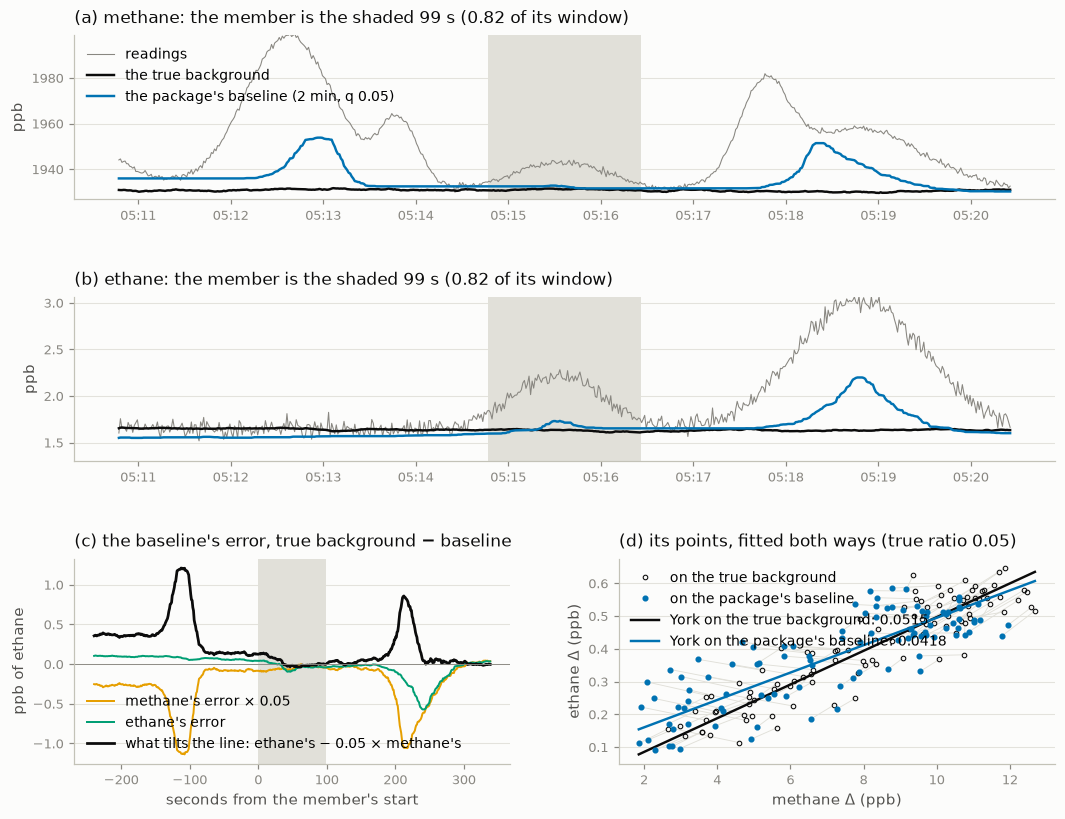

true background      slope 0.0515 ± 0.0022   truth 0.7σ away
noise only           slope 0.0418 ± 0.0027   truth 3.0σ away
with the allowance   slope 0.0418 ± 0.0040   truth 2.0σ away


In [16]:
# The illustrative member: a crowded one (more than 3/4 of its window), at the
# shortest window, at least 30 points, whose fit on the true background is
# within 1 sigma of the truth and whose noise-only sigma misses it by 2 or more:
# among those, the one whose slope misses the truth by the most.
expected = np.where(share >= 0.5, RATIO_A, RATIO_B)
z_noise = ((noise_only.slope - expected) / noise_only.slope_sigma_widened).to_numpy()
z_true = ((on_truth.slope - expected) / on_truth.slope_sigma_widened).to_numpy()
shortest = (on_truth.baseline_window == on_truth.baseline_window.min()).to_numpy()
# Its fit on the true background within 1 sigma of the truth, so that what goes
# wrong is the baseline's.
pick = np.flatnonzero(
    good
    & shortest
    & (on_truth.n >= 30).to_numpy()
    & (fill > 0.75)
    & (np.abs(z_true) < 1)
    & (np.abs(z_noise) >= 2)
)
miss = np.abs(noise_only.slope.to_numpy() - expected)
i = int(pick[np.argmax(miss[pick])])
member = noise_only.iloc[i]
W, Q = float(member.baseline_window), float(member.baseline_quantile)
start, end = pd.Timestamp(member.start_time), pd.Timestamp(member.end_time)
t = pd.to_datetime(pairs.time.values)
inside = (t >= start) & (t < end)
at = dict(baseline_window=W, baseline_quantile=Q)
read = {g: pairs[g].values for g in ("ch4", "c2h6")}
baseline = {g: read[g] - pairs[f"enhancement_{g}"].sel(at).values for g in read}
background = {g: np.asarray(truth[f"background_{g}"]) for g in read}
error = {g: background[g] - baseline[g] for g in read}  # Δ = Δ_true + error
true_ratio = RATIO_A if share[i] >= 0.5 else RATIO_B
view = (t >= start - pd.Timedelta("4min")) & (t < end + pd.Timedelta("4min"))

fig = plt.figure(figsize=(11.5, 8.6))
grid = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.25], hspace=0.55, wspace=0.25)
for r, (g, name, pad) in enumerate((("ch4", "methane", 3.0), ("c2h6", "ethane", 0.25))):
    ax = fig.add_subplot(grid[r, :])
    ax.axvspan(start, end, color=GRID, lw=0)
    ax.plot(t[view], read[g][view], color=MUTED, lw=0.7, label="readings")
    ax.plot(t[view], background[g][view], color=INK, lw=1.6, label="the true background")
    ax.plot(
        t[view],
        baseline[g][view],
        color=C1,
        lw=1.6,
        label=f"the package's baseline ({W / 60:g} min, q {Q:g})",
    )
    low = np.nanpercentile(np.r_[background[g][view], baseline[g][view]], 1) - pad
    ax.set_ylim(low, np.nanpercentile(read[g][view], 99.5))
    finish(
        ax,
        title=f"({'ab'[r]}) {name}: the member is the shaded {(end - start).total_seconds():.0f} s "
        f"({(end - start).total_seconds() / W:.2f} of its window)",
        ylab="ppb",
        legend=(r == 0),
        loc="upper left",
    )
    clock(ax, "%H:%M")
ax = fig.add_subplot(grid[2, 0])
seconds = (t[view] - start).total_seconds()
ax.axvspan(0, (end - start).total_seconds(), color=GRID, lw=0)
ax.plot(
    seconds,
    true_ratio * error["ch4"][view],
    color=C2,
    lw=1.3,
    label=f"methane's error × {true_ratio:g}",
)
ax.plot(seconds, error["c2h6"][view], color=C3, lw=1.3, label="ethane's error")
ax.plot(
    seconds,
    error["c2h6"][view] - true_ratio * error["ch4"][view],
    color=INK,
    lw=1.8,
    label=f"what tilts the line: ethane's − {true_ratio:g} × methane's",
)
ax.axhline(0, color=MUTED, lw=0.6)
finish(
    ax,
    title="(c) the baseline's error, true background − baseline",
    xlab="seconds from the member's start",
    ylab="ppb of ethane",
    legend=True,
    loc="lower left",
)
ax = fig.add_subplot(grid[2, 1])
x_true = read["ch4"][inside] - background["ch4"][inside]
y_true = read["c2h6"][inside] - background["c2h6"][inside]
x_pkg = pairs["enhancement_ch4"].sel(at).values[inside]
y_pkg = pairs["enhancement_c2h6"].sel(at).values[inside]
for a, b, c, d in zip(x_true, y_true, x_pkg, y_pkg):
    ax.plot([a, c], [b, d], color=GRID, lw=0.6, zorder=1)
ax.plot(
    x_true,
    y_true,
    "o",
    ms=3,
    mfc="none",
    mec=INK,
    mew=0.7,
    zorder=2,
    label="on the true background",
)
ax.plot(x_pkg, y_pkg, "o", ms=3, color=C1, zorder=3, label="on the package's baseline")
span = np.array([np.nanmin(np.r_[x_true, x_pkg]), np.nanmax(np.r_[x_true, x_pkg])])
for fits, colour, label in (
    (on_truth, INK, "true background"),
    (noise_only, C1, "package's baseline"),
):
    row = fits.iloc[i]
    ax.plot(
        span,
        row.intercept + row.slope * span,
        color=colour,
        lw=1.6,
        label=f"York on the {label}: {row.slope:.4f}",
    )
finish(
    ax,
    title=f"(d) its points, fitted both ways (true ratio {true_ratio:g})",
    xlab="methane Δ (ppb)",
    ylab="ethane Δ (ppb)",
    legend=True,
    loc="upper left",
)
plt.show()
for label, fits in (
    ("true background", on_truth),
    ("noise only", noise_only),
    ("with the allowance", with_error),
):
    row = fits.iloc[i]
    print(
        f"{label:20s} slope {row.slope:.4f} ± {row.slope_sigma_widened:.4f}   "
        f"truth {abs(row.slope - true_ratio) / row.slope_sigma_widened:.1f}σ away"
    )

**Read it.** The ethane plume fills 0.82 of the 2 min window, so in (b) the
ethane baseline rises under it and eats part of its middle, where the plume is
tallest; the methane baseline (a) barely moves. In (c) the error that tilts the
line, ethane's less 0.05 × methane's, is largest at the plume's middle, and in
(d) the line on the package's baseline reads 0.0418 against 0.0515 on the true
background: 3.0σ from the truth with the readings' noise alone, 2.0σ with the
baseline allowance. This is crowding, and the crowding gate leaves this member
out (more than 3/4 of its window); the plume is read at a longer window.


In [17]:
results, rows = {}, []
for name, fits in (
    ("baseline, noise only", noise_only),
    ("baseline, with the allowance", with_error),
    ("the true background", on_truth),
):
    error = ((fits.slope[good] - truth_ratio) / fits.slope_sigma_widened[good]).to_numpy()
    results[name] = error
    gate_ok = fits.mswd[good] / fits.mswd_expected[good] <= mswd_gate(fits.dof[good])
    rows.append(
        {
            "fitted on": name,
            "within ±2σ": f"{np.mean(np.abs(error) <= 2):.0%}",
            "robust spread (σ)": round(1.4826 * np.median(np.abs(error - np.median(error))), 2),
            "turned away by the one-source gate": f"{(~gate_ok).sum()} ({(~gate_ok).mean():.0%})",
            "median baseline factor": round(float(fits.baseline_factor[good].median()), 2),
        }
    )
print(pd.DataFrame(rows).to_string(index=False))
roomy = good & (fill <= 0.75)
for name, fits in (("noise only", noise_only), ("with the allowance", with_error)):
    miss = (
        np.abs(fits.slope[roomy] - np.where(share[roomy] >= 0.5, RATIO_A, RATIO_B))
        <= 2 * fits.slope_sigma_widened[roomy]
    )
    print(
        f"crowded members left out (the crowding gate at 3/4): {roomy.sum()} members, "
        f"{name} {miss.mean():.0%} within ±2σ"
    )

                   fitted on within ±2σ  robust spread (σ) turned away by the one-source gate  median baseline factor
        baseline, noise only        71%               1.82                           99 (17%)                    1.00
baseline, with the allowance        95%               1.07                            53 (9%)                    1.69
         the true background        94%               0.89                             0 (0%)                    1.00
crowded members left out (the crowding gate at 3/4): 407 members, noise only 72% within ±2σ
crowded members left out (the crowding gate at 3/4): 407 members, with the allowance 93% within ±2σ


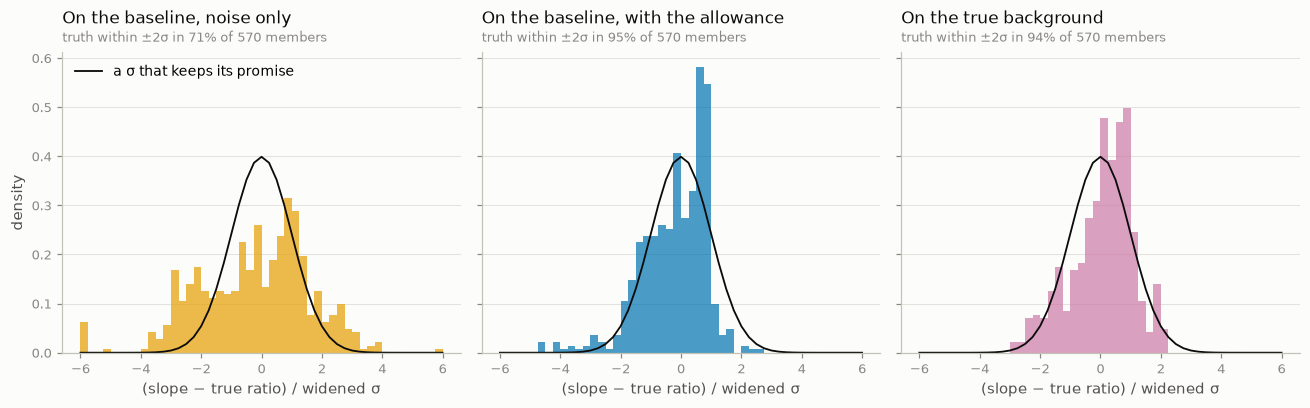

  ✔ §6 on the true background, the widened sigma is honest for single-source members   [spread 0.89 sigma, 94% within ±2 sigma]
  ✔ §6 with the baseline allowance the widened sigma covers at least 90 % of the good members   [noise only 71%, with the allowance 95%]


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
bins = np.linspace(-6, 6, 49)
curve = np.exp(-0.5 * bins**2) / math.sqrt(2 * math.pi)
for ax, (name, error), color in zip(axes, results.items(), (C2, C1, C4)):
    ax.hist(np.clip(error, -6, 6), bins=bins, density=True, color=color, alpha=0.7)
    ax.plot(bins, curve, color=INK, lw=1.2, label="a σ that keeps its promise")
    finish(
        ax,
        title=f"On the {name}" if name.startswith("baseline") else f"On {name}",
        sub=f"truth within ±2σ in {np.mean(np.abs(error) <= 2):.0%} of {len(error)} members",
        xlab="(slope − true ratio) / widened σ",
        legend=(ax is axes[0]),
        loc="upper left",
    )
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

spread = {name: 1.4826 * np.median(np.abs(e - np.median(e))) for name, e in results.items()}
covered = {name: np.mean(np.abs(e) <= 2) for name, e in results.items()}
check(
    "§6 on the true background, the widened sigma is honest for single-source members",
    len(results["the true background"]) >= 50
    and 0.8 <= spread["the true background"] <= 1.25
    and covered["the true background"] >= 0.88,
    f"spread {spread['the true background']:.2f} sigma, "
    f"{covered['the true background']:.0%} within ±2 sigma",
)
check(
    "§6 with the baseline allowance the widened sigma covers at least 90 % of the good members",
    covered["baseline, with the allowance"] >= 0.9
    and covered["baseline, with the allowance"] >= covered["baseline, noise only"],
    f"noise only {covered['baseline, noise only']:.0%}, with the allowance "
    f"{covered['baseline, with the allowance']:.0%}",
)

**Read the table.** With the readings' noise only, the same members scatter
1.8 times as far as their σ says (71 % within ±2σ), and the one-source gate
turns away a sixth of them, each one source, false alarms like §3's candidate
13. With the baseline allowance the widened σ covers 95 % at a robust spread
of 1.07, and the gate turns away 9 %: half as many, though still more than the
1 % a 99 % gate promises (`METHODS.md` §5.4). On the true background there is
no baseline error to hold, and the readings' noise alone is honest (94 %,
spread 0.89). The median baseline factor, 1.7, is how much wider the σ became.
Leaving out the crowded members (the crowding gate) keeps 407 of the 570 and
changes little here: on this air the allowance happens to cover crowded members
too (below). (The histograms are lumpy because a candidate's members share
their air and miss together; counted one per candidate the coverage is about
the same, `METHODS.md` §5.4.)

Two cautions. The wobble's size is a calibration on generated air, not a
derivation (§5.4). And the wander is measured on every reading outside the
events, which on this air includes the tails of plumes and plumes too small
to be events, and reads them as wander; where the background really wanders
that part is small beside it, on flat air (the first Try-it) it makes the σ
too wide. It is also why the true-background fits are made with
`baseline_error=False`: their wander would be only the air's small plumes.

**Crowding and drift, window by window.** To tell the two apart, the baseline
is recomputed with every event's readings masked (every entry and exit at
that window and quantile), so that no plume sits in any window, and every
member is refitted on it. Then the slope's error splits exactly into two
parts: **crowding**, the package's baseline against the masked one (what the
plumes' own readings in the windows did), and **drift**, the masked baseline
against the true background (what the background did). Where a long event
leaves a window too few clean readings, the masked baseline is blank and the
member is left out of the split. Beside it, coverage for the crowded members
(more than 3/4 of their window) and for the rest.

In [19]:
CROWDED = 0.75  # the crowding gate's default: a member longer than this share of its window

mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
catalog = products["catalog"]
masked_pairs = pairs.copy(deep=True)
for g in ("ch4", "c2h6"):
    masked_pairs[f"enhancement_{g}"] = masked_pairs[f"enhancement_{g}"] * np.nan
for w in pairs.baseline_window.values:
    for q in pairs.baseline_quantile.values:
        events = catalog[(catalog.baseline_window == w) & (catalog.baseline_quantile == q)]
        count = np.zeros(mid.size + 1, dtype=int)
        np.add.at(
            count,
            np.searchsorted(mid, pd.to_datetime(events.start_time).values.astype(np.int64)),
            1,
        )
        np.add.at(
            count, np.searchsorted(mid, pd.to_datetime(events.end_time).values.astype(np.int64)), -1
        )
        in_event = np.cumsum(count)[:-1] > 0
        masked = stream.copy()
        for g in ("ch4", "c2h6"):
            masked[g] = masked[g].where(~in_event)
        state = baseline_state(
            masked,
            instrument="van",
            baseline=BaselineConfig(windows=[f"{int(w)}s"], quantiles=[float(q)]),
        )
        here = dict(baseline_window=w, baseline_quantile=q)
        for g in ("ch4", "c2h6"):
            masked_pairs[f"enhancement_{g}"].loc[here] = (
                pairs[g].values - state[f"baseline_{g}"].sel(here).values
            )
on_masked = member_fits(
    masked_pairs,
    catalog,
    PairColumns("enhancement_c2h6", "enhancement_ch4", "c2h6", "ch4"),
    reference="van.ch4",
    numerator="van.c2h6",
    period="native",
    methods=("york",),
    baseline_error=False,
).reset_index(drop=True)
complete = ((on_masked.status == "OK") & (on_masked.n == noise_only.n)).to_numpy()
truth_all = np.where(share >= 0.5, RATIO_A, RATIO_B)


def covers(fits, keep):
    """Share of the members in keep whose widened sigma holds the truth at 2 sigma."""
    if not keep.any():
        return math.nan
    return float(
        np.mean(np.abs(fits.slope[keep] - truth_all[keep]) <= 2 * fits.slope_sigma_widened[keep])
    )


def pct(value):
    """Return a share as a percent, a dash where there is none."""
    return "–" if math.isnan(value) else f"{value:.0%}"


def both_ways(fits, crowded, rest):
    """Return the coverage of the crowded members and of the rest, as 'a / b'."""
    return f"{pct(covers(fits, crowded))} / {pct(covers(fits, rest))}"


def robust(v):
    """1.4826 x the median absolute deviation: a standard deviation that ignores outliers."""
    return float(1.4826 * np.median(np.abs(v - np.median(v))))


split = []
for w in sorted(on_truth.baseline_window[good].unique()):
    here = good & (on_truth.baseline_window == w).to_numpy()
    crowded, rest, both = here & (fill > CROWDED), here & (fill <= CROWDED), here & complete
    sigma = noise_only.slope_sigma_widened.to_numpy()
    split.append(
        {
            "window": f"{w / 60:g} min",
            "members": int(here.sum()),
            f"crowded (> {CROWDED:g})": int(crowded.sum()),
            "noise only: crowded / rest": both_ways(noise_only, crowded, rest),
            "allowance: crowded / rest": both_ways(with_error, crowded, rest),
            "slope moved by crowding (σ)": round(
                robust(((noise_only.slope - on_masked.slope).to_numpy() / sigma)[both]), 2
            ),
            "by drift (σ)": round(
                robust(((on_masked.slope - on_truth.slope).to_numpy() / sigma)[both]), 2
            ),
            "split from": int(both.sum()),
        }
    )
split = pd.DataFrame(split)
print(split.to_string(index=False))

shortest = split.iloc[0]
low, high = (float(v.strip("%")) / 100 for v in shortest["noise only: crowded / rest"].split(" / "))
check(
    "§6 at the shortest window, crowded members cover less than the rest with the noise alone",
    low < high,
    shortest["noise only: crowded / rest"],
)
gated = good & (fill <= CROWDED)
check(
    "§6 with the crowding gate and the allowance, the good members are covered within 5 points of "
    "the true background's own fits",
    covers(with_error, gated) >= covers(on_truth, gated) - 0.05,
    f"{covers(with_error, gated):.0%} against {covers(on_truth, gated):.0%}, {gated.sum()} members",
)

window  members  crowded (> 0.75) noise only: crowded / rest allowance: crowded / rest  slope moved by crowding (σ)  by drift (σ)  split from
 2 min      249               154                  69% / 88%                 99% / 91%                         0.26          0.53          57
10 min      180                 9                  33% / 67%               100% / 100%                         0.16          0.98         155
60 min      141                 0                    – / 67%                   – / 87%                         0.04          0.77         141
  ✔ §6 at the shortest window, crowded members cover less than the rest with the noise alone   [69% / 88%]
  ✔ §6 with the crowding gate and the allowance, the good members are covered within 5 points of the true background's own fits   [93% against 95%, 407 members]


**Read it.** At the 2 min window most of the good members (154 of 249) fill
more than 3/4 of their window, and with the noise alone they cover 69 %
against 88 % for the rest. Split exactly, crowding moves the slopes by 0.26 σ
at 2 min, 0.16 σ at 10 min and almost nothing at 60 min (0.04 σ), as a plume
shorter beside its window crowds it less; drift moves them by 0.5 to 1 σ at
every window. So the two problems are real and different: crowding is a short
window's, drift is everyone's.

On this generated air the allowance covers the crowded members too (99 % at
2 min): its wobble, calibrated on this air, stands in for crowding. On real
air with known plumes added it does not (crowded members covered 70–72 %,
`METHODS.md` §5.3), which is why crowding is the crowding gate's to handle,
and why the plume is then read at a longer window.

**Try it.**

* `WALK_CH4 = 0.0` and `WALK_C2H6 = 0.0`: flat backgrounds. The drift part
  vanishes at 10 and 60 min (0.03 σ and 0.00 σ) and crowding is what is left
  at 2 min. The noise alone now covers 89 %; with the allowance 98 %, at a
  robust spread of 0.77, a σ about a quarter too wide (the small plumes read
  as wander). The gate turns away 4 % on the noise only and 2 % with the
  allowance.
* `PURITY = 0.95`: members up to 5 % from the other source join (867 of them).
  On the true background coverage falls from 94 % to 90 %, since such a member
  is a little mixed; with the allowance from 95 % to 90 %, and on the noise
  only from 71 % to 69 %.
* `CROWDED = 0.5`: a stricter line between crowded and not. At 2 min 209 of
  the 249 members now count as crowded, and the 40 left cover 100 % with the
  noise alone; the members the stricter gate keeps (343) are covered 94 % with
  the allowance, as the true background's own fits cover them. The crowding
  and drift columns do not move: the split does not depend on the line.

---
## §7 The gates, and the plateau's trade

A gate never changes a fit; it decides whether the fit counts. So the fit
table stores the numbers (§3) and a gate is a threshold applied afterwards.
Each gate in `ratios.gates` is a *list*, swept like a window, at no cost in
refitting (`METHODS.md` §5.3):

| gate | a member counts when | default |
|---|---|---|
| height | $z_\text{peak} \ge z_\text{min}$, read on the candidate's tallest member (`candidate_peak_z`) | $z_\text{min} = 5$ |
| points | $n \ge n_\text{min}$ (`n`) | $n_\text{min} = 8$ |
| signal | $\text{signal} \ge s_\text{min}$ (`signal`, §3) | $s_\text{min} = 2$ |
| one source | $\text{MSWD} \le \chi^2_{p,\;n-2} \,/\, (n - 2)$ (`mswd`, `dof`) | $p = 0.99$ |
| plateau | the same, with the plateau's `plateau_mswd` and `plateau_dof` | off ($p = 1$) |

With a declared $\tau$, a single source's MSWD centres on $E$ rather than 1
(§5), so the one-source gate should read $\text{MSWD} / E$; 7c2, which applies
the gates, does. Here no $\tau$ is declared and $E = 1$.

The **plateau** refits each member over twice its width, centred on it. The
hope: a member that only *looks* like one source, because its interval stops
short of a neighbour, fails once the window reaches the neighbour. Measured
here on six hours of two sources, the recipe saying which members are one
source (at least 95 % of their methane from one) and which are mixtures.

In [20]:
start_section("§7")
# --- parameters --------------------------------------------------------------
SEED = 1
HOURS = 6.0  # a longer record, for enough members
MIN_PEAK_Z = 5.0  # height gate
MIN_SIGNAL = 2.0  # signal gate
PLATEAU_PROBABILITY = 0.99  # the plateau gate when on

products = chain(seed=SEED, hours=HOURS)
fits, pairs = products["fits"], products["paired"].dataset
share, largest = source_share(fits, products["truth"], pairs)
york_rows = fits.assign(kind=kind_of(share, largest))
york_rows = york_rows[york_rows.method == "york"]
eligible = york_rows[
    (york_rows.status == "OK")
    & (york_rows.candidate_peak_z >= MIN_PEAK_Z)
    & (york_rows.n >= 8)
    & (york_rows.signal >= MIN_SIGNAL)
]
one_source = eligible.mswd <= mswd_gate(eligible.dof)
plateau = eligible.plateau_mswd <= mswd_gate(eligible.plateau_dof, PLATEAU_PROBABILITY)
single = eligible.kind.isin(["A", "B"])
mixture = eligible.kind == "mixture"
rules = {
    "height, points and signal only": np.ones(len(eligible), bool),
    "+ one source (the default)": one_source.to_numpy(),
    "+ one source + plateau": (one_source & plateau).to_numpy(),
}
rows = []
for name, keep in rules.items():
    kept_single, kept_mixture = (keep & single).sum(), (keep & mixture).sum()
    rows.append(
        {
            "rule": name,
            "single-source members kept": f"{kept_single} ({kept_single / single.sum():.0%})",
            "mixtures kept": f"{kept_mixture} ({kept_mixture / mixture.sum():.0%})",
        }
    )
print(
    f"{len(eligible)} members pass height, points and signal: "
    f"{single.sum()} single-source, {mixture.sum()} mixtures\n"
)
print(pd.DataFrame(rows).to_string(index=False))

1716 members pass height, points and signal: 854 single-source, 862 mixtures

                          rule single-source members kept mixtures kept
height, points and signal only                 854 (100%)    862 (100%)
    + one source (the default)                  652 (76%)       44 (5%)
        + one source + plateau                  335 (39%)        4 (0%)


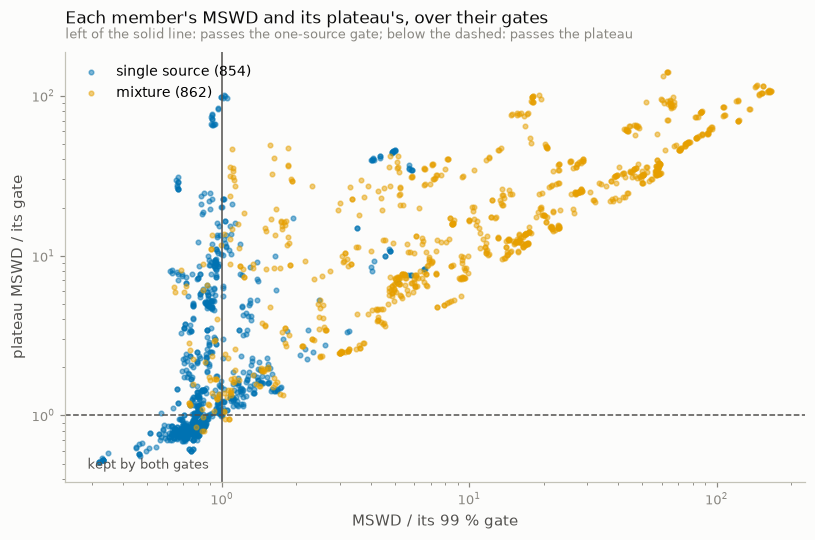

  ✔ §7 the stored plateau is York's own over twice the member's width, centred on it   [30 members]
  ✔ §7 the one-source gate keeps a larger share of single-source members than of mixtures   [76% against 5%]


In [21]:
fig, ax = plt.subplots(figsize=(7.5, 5))
x = eligible.mswd / mswd_gate(eligible.dof)
y = eligible.plateau_mswd / mswd_gate(eligible.plateau_dof, PLATEAU_PROBABILITY)
ax.scatter(x[single], y[single], s=9, color=C1, alpha=0.5, label=f"single source ({single.sum()})")
ax.scatter(x[mixture], y[mixture], s=9, color=C2, alpha=0.5, label=f"mixture ({mixture.sum()})")
ax.axvline(1, color=INK2, lw=1)
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.text(0.03, 0.03, "kept by both gates", transform=ax.transAxes, color=INK2, fontsize=8.5)
finish(
    ax,
    title="Each member's MSWD and its plateau's, over their gates",
    sub="left of the solid line: passes the one-source gate; below the dashed: passes the plateau",
    xlab="MSWD / its 99 % gate",
    ylab="plateau MSWD / its gate",
    legend=True,
    loc="upper left",
    grid_axis=None,
)
plt.tight_layout()
plt.show()

# The stored plateau is York's own over twice the member's width, centred, for a sample of members.
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
same, sample = True, eligible.sample(30, random_state=0) if len(eligible) >= 30 else eligible
for row in sample.itertuples():
    start, stop = pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
    centre, half = start + (stop - start) // 2, stop - start
    points = reference_points(mid, centre - half, centre + half)
    at = dict(baseline_window=row.baseline_window, baseline_quantile=row.baseline_quantile)
    line = york(
        pairs["enhancement_ch4"].sel(at).values[points],
        pairs["enhancement_c2h6"].sel(at).values[points],
        pairs["sigma_rand_ch4"].values[points],
        pairs["sigma_rand_c2h6"].values[points],
    )
    same &= np.array_equal(row.plateau_slope, line.slope[0]) and np.array_equal(
        row.plateau_mswd, line.mswd[0]
    )
check(
    "§7 the stored plateau is York's own over twice the member's width, centred on it",
    same,
    f"{len(sample)} members",
)
check(
    "§7 the one-source gate keeps a larger share of single-source members than of mixtures",
    one_source[single].mean() > one_source[mixture].mean(),
    f"{one_source[single].mean():.0%} against {one_source[mixture].mean():.0%}",
)

The one-source gate keeps three quarters of the single-source members, not
all of them, for two reasons: §6's baseline error, which turns some away
however pure they are (half as many once the fits hold it, §6), and the 5 %
of the other source a member may hold here
(single-source means at least 95 %, against §6's 99.9 %), enough to bend a
tall member's line.

The plateau does what it was meant to: most of the mixtures the one-source
gate lets through fail it. But it fails about half of the good single-source
members too (the many blue points above the dashed line), because a window
twice as wide reaches a neighbour as often as it reaches the rest of a
mixture: it rejects *a neighbour nearby* as readily as *a mixture*. So its
numbers are stored and its gate is off by default; the sweep summary (7c2)
will show the trade with the gate on and off side by side
(`ratios.gates.plateau_probability: [0.99, 1.0]`).

**Try it.**

* `MIN_SIGNAL = 0.0`: 165 weaker members join (136 single-source, 29
  mixtures), and the one-source gate now lets 8 % of the mixtures through
  instead of 5 %: where methane barely swings, the MSWD has little to judge
  by. That is what the signal gate is for.
* `PLATEAU_PROBABILITY = 0.9999`: a looser plateau keeps 45 % of the
  single-source members instead of 39 %, and 1 % of the mixtures instead of
  under 1 %: the trade moves, it does not go away.

---
## §8 Two instruments on one clock

A ratio across two instruments needs both gases on the same cells. Pairing
(`tsara.align.pair_species`, `METHODS.md` §1.3, §11.4) puts them on the
**pair clock**: the cells of the wider-supported instrument, the other
averaged onto them, each reading weighted by the time it shares with the
cell, its sigma propagated through the same weights. Nothing is ever copied
onto a narrower cell.

Three things are new in 7c1:

* **The sweep travels.** An enhancement has one version per (window,
  quantile). Each sweep point is paired as if alone: a cell is a pair *there*
  when both gases have a value there, and a row that is a pair at no point is
  dropped (§11.4, "Swept pairs").
* **Readings ride along** (`carry=`), so that each pair holds the readings'
  own sigma, which is what weighs a fit (`METHODS.md` §4.3).
* **The pair clock can be chosen**: `native` (the rule above) or a period such
  as `10s`, every value averaged onto it (`ratios.periods`).

Here the reference is a 2 s analyzer's methane ('picarro') and the numerator
the 1 s analyzer's ethane ('aeris'), from the same air.

In [22]:
start_section("§8")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
OFFSET = 0.0  # where the 2 s analyzer's cells start after each even second: 0.0 or 0.5
PERIOD = "native"  # the pair clock: "native" (the wider cells) or a duration such as "10s"
WINDOW = 600.0  # the sweep point drawn below: baseline window (s)
QUANTILE = 0.05  # and quantile

run = two_analyzers(seed=SEED, offset_s=OFFSET, period=PERIOD)
paired = run["paired"]
pairs = paired.dataset
print(f"pair clock: {paired.clock} ({pairs.attrs['tsara_pairing_clock_reason']})")
counts = np.array(pairs.attrs["tsara_pairing_pairs_per_sweep_point"]).reshape(
    pairs.sizes["baseline_window"], pairs.sizes["baseline_quantile"]
)
table = pd.DataFrame(
    counts,
    index=[f"{w / 60:g} min" for w in pairs.baseline_window.values],
    columns=[f"q {q:g}" for q in pairs.baseline_quantile.values],
)
print(f"\npairs at each sweep point (of {paired.n_pairs} rows kept):")
print(table.to_string())
ethane = paired.y_name
print(
    f"\nethane: {pairs[ethane].attrs['tsara_n_readings']} readings behind the pairs, "
    f"borrowed share {pairs[ethane].attrs['tsara_borrowed_share']:.2f}, "
    f"readings in more than one pair {pairs[ethane].attrs['tsara_shared_readings']}"
)

pair clock: picarro (wider cells (2 s vs 1 s))

pairs at each sweep point (of 1799 rows kept):
        q 0.01  q 0.05  q 0.1
2 min        0    1799   1799
10 min    1799    1799   1799
60 min    1799    1799   1799

ethane: 3598 readings behind the pairs, borrowed share 0.00, readings in more than one pair 0


At 2 min and q 0.01 nothing pairs: the 2 s analyzer's 2 min windows hold 60
readings, and a 1st percentile needs 100 (`METHODS.md` §6.4), so its
baseline, and its enhancement, is blank there. Every other sweep point pairs
on its own rows.

The figure takes 90 s around the strongest plume of the ethane-bearing source
A (the recipe knows where it is): the 1 s ethane readings over their
baseline, and the values pairing put on each cell of the clock.

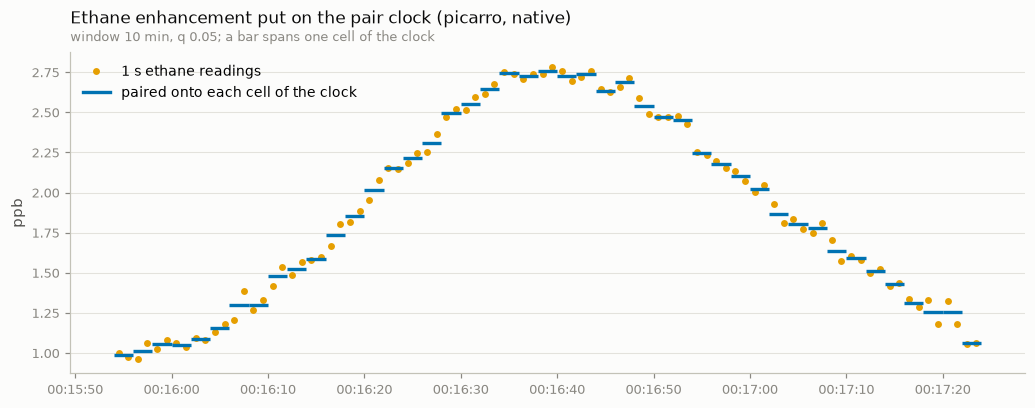

In [23]:
peak = START + pd.Timedelta(seconds=int(np.argmax(run["truth"]["A"])))
lo, hi = peak - pd.Timedelta("45s"), peak + pd.Timedelta("45s")

aeris = run["states"]["aeris"]
reading = aeris["enhancement_c2h6"].sel(baseline_window=WINDOW, baseline_quantile=QUANTILE)
shown = (aeris.time.values >= np.datetime64(lo)) & (aeris.time.values < np.datetime64(hi))
cells = pairs.time_bnds.values
inside = (cells[:, 0] >= np.datetime64(lo)) & (cells[:, 1] <= np.datetime64(hi))
joined = pairs[ethane].sel(baseline_window=WINDOW, baseline_quantile=QUANTILE).values

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(
    aeris.time.values[shown],
    reading.values[shown],
    "o",
    color=C2,
    ms=3.5,
    label="1 s ethane readings",
)
for (start, stop), value in zip(cells[inside], joined[inside]):
    ax.plot([start, stop], [value, value], color=C1, lw=2.2, solid_capstyle="butt")
ax.plot([], [], color=C1, lw=2.2, label="paired onto each cell of the clock")
finish(
    ax,
    title=f"Ethane enhancement put on the pair clock ({paired.clock}, {PERIOD})",
    sub=f"window {WINDOW / 60:g} min, q {QUANTILE:g}; a bar spans one cell of the clock",
    ylab="ppb",
    legend=True,
    loc="upper left",
)
clock(ax, "%H:%M:%S")
plt.tight_layout()
plt.show()

In [24]:
# 1. Every sweep point, swept and alone: the pairing of that point by itself.
alone_ok, compared = True, 0
for i, w in enumerate(pairs.baseline_window.values):
    for j, q in enumerate(pairs.baseline_quantile.values):
        if counts[i, j] == 0:
            continue
        alone = {
            name: state.isel(baseline_window=i, baseline_quantile=j)
            for name, state in run["states"].items()
        }
        single = pair_species(
            alone,
            ("aeris", "enhancement_c2h6"),
            ("picarro", "enhancement_ch4"),
            carry=[("aeris", "c2h6"), ("picarro", "ch4")],
            target=None if PERIOD == "native" else PERIOD,
        ).dataset
        at = pairs.isel(baseline_window=i, baseline_quantile=j)
        here = at.isel(time=np.flatnonzero(np.isfinite(at[ethane].values)))
        for name in single.data_vars:
            alone_ok &= np.array_equal(here[name].values, single[name].values, equal_nan=True)
        compared += 1
check(
    "§8 every sweep point is bit for bit what pairing it alone gives",
    alone_ok,
    f"{compared} sweep points with pairs, every column",
)

# 2. The averaging itself, by the loop in the setup cell, at the drawn sweep point.
bounds = aeris.time_bnds.values.astype("datetime64[ns]").astype(np.int64)
sigma = aeris["sigma_rand_c2h6"].values
cell_ns = cells.astype("datetime64[ns]").astype(np.int64)
worst_value = worst_sigma = 0.0
for k in np.flatnonzero(np.isfinite(joined)):
    near = slice(
        max(0, np.searchsorted(bounds[:, 1], cell_ns[k, 0]) - 1),
        np.searchsorted(bounds[:, 0], cell_ns[k, 1]) + 1,
    )
    value, value_sigma = reference_join(
        bounds[near], reading.values[near], sigma[near], *cell_ns[k]
    )
    worst_value = max(worst_value, abs(value - joined[k]))
    worst_sigma = max(worst_sigma, abs(value_sigma - pairs["sigma_rand_c2h6"].values[k]))
check(
    "§8 each paired ethane value is the overlap-weighted mean of the readings in its cell",
    worst_value < 1e-9,
    f"largest difference {worst_value:.1e} ppb",
)
check(
    "§8 the carried reading sigma is sqrt(sum w^2 sigma^2) / sum w over the same readings",
    worst_sigma < 1e-12,
    f"largest difference {worst_sigma:.1e} ppb",
)

  ✔ §8 every sweep point is bit for bit what pairing it alone gives   [8 sweep points with pairs, every column]
  ✔ §8 each paired ethane value is the overlap-weighted mean of the readings in its cell   [largest difference 0.0e+00 ppb]
  ✔ §8 the carried reading sigma is sqrt(sum w^2 sigma^2) / sum w over the same readings   [largest difference 0.0e+00 ppb]


**Try it.**

* `OFFSET = 0.5`: the 2 s cells now straddle the 1 s readings. Each cell
  takes half of a reading at each end, so a quarter of each paired value rests
  on air outside its cell (borrowed share 0.25), and 1,798 of the 3,599
  readings sit in two pairs (`tsara_shared_readings`). The averaging checks
  still hold: the overlap weights carry it.
* `PERIOD = "10s"`: both gases are averaged onto a 10 s clock (`explicit`):
  360 rows instead of 1,799, a fifth as many at every sweep point, which is
  what starves a short event of points.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook or the
truth the recipe manufactured.

In [25]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

27 of 27 checks hold

  ✔ §1 members are the distinct (candidate, quantile, exit) intervals, named by lowest entry   [389 members]
  ✔ §1 each member is fitted once per estimator   [778 rows]
  ✔ §2 each member's points are the cells whose midpoint its interval holds   [389 of 389 members of the hour]
  ✔ §2 entry copies hold one interval   [389 (candidate, quantile, exit) groups]
  ✔ §2 on the reference's own cells, midpoint membership is the event index   [every reading of all 81 sweep points]
  ✔ §3 the stored lines are York's and least squares' on the member's points alone   [4 of 4 members: slope, intercept, sigma, r2]
  ✔ §3 the MSWD is the mean squared divided residual over n - 2   [4 of 4]
  ✔ §3 dof is n - 2, and least squares' row carries York's MSWD
  ✔ §3 every member shown that is 99.9 % one source passes its gate on the true background   [3 members]
  ✔ §3 every fit names its sigmas as the recipe declared them   [389 York fits]
  ✔ §3 every row carries its candidate's tal